# PDAN8412 Final Portfolio of Evidence
## CIFAR-10 Image Recognition with Convolutional Neural Networks

**Student:** Boitumelo Malinga  
**Student number:** ST10107491  

This notebook uses Spark for data-quality analysis and EDA, then trains and compares three TensorFlow CNN models. CIFAR-10 contains 60,000 RGB images across 10 balanced classes. Dataset source: https://www.cs.toronto.edu/~kriz/cifar.html

## 1. Imports and Configuration

In [1]:
# All imports are kept together at the top of the notebook.
import os
import sys
import json
import random
import hashlib
import platform
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve,
    auc,
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

import pyspark
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.types import (
    StructType,
    StructField,
    StringType,
    IntegerType,
    DoubleType,
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")

In [2]:
# Reproducibility and training controls.
SEED = 42
FAST_MODE = False  # Keep False for the final submitted run.
BATCH_SIZE = 128
BASELINE_EPOCHS = 3 if FAST_MODE else 15
REGULARISED_EPOCHS = 5 if FAST_MODE else 40
RESIDUAL_EPOCHS = 5 if FAST_MODE else 40
VALIDATION_SIZE = 0.10

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass

CLASS_NAMES = np.array([
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
])

OUTPUT_DIR = Path("final_poe_outputs")
FIGURE_DIR = OUTPUT_DIR / "figures"
TABLE_DIR = OUTPUT_DIR / "tables"
MODEL_DIR = OUTPUT_DIR / "models"

for directory in [OUTPUT_DIR, FIGURE_DIR, TABLE_DIR, MODEL_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print(f"Python: {sys.version.split()[0]}")
print(f"TensorFlow: {tf.__version__}")
print(f"PySpark: {pyspark.__version__}")
print(f"scikit-learn: {sklearn.__version__}")
print("TensorFlow devices:", tf.config.list_physical_devices())

Python: 3.11.16
TensorFlow: 2.21.0
PySpark: 3.5.9
scikit-learn: 1.9.1
TensorFlow devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


## 2. Start Spark

In [3]:
spark = (
    SparkSession.builder
    .appName("PDAN8412_Final_POE_CIFAR10")
    .master("local[*]")
    .config("spark.driver.memory", "4g")
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("ERROR")
print("Spark version:", spark.version)

26/11/15 13:45:38 WARN Utils: Your hostname, Boitumelos-MacBook-Pro.local resolves to a loopback address: 127.0.0.1; using 10.0.0.110 instead (on interface en0)
26/11/15 13:45:38 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/15 13:45:39 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark version: 3.5.9


## 3. Load CIFAR-10

In [4]:
# TensorFlow downloads CIFAR-10 automatically the first time this cell runs.
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.cifar10.load_data()
y_train_full = y_train_full.reshape(-1).astype(np.int32)
y_test = y_test.reshape(-1).astype(np.int32)

if FAST_MODE:
    # This branch is only for quick debugging. Do not submit FAST_MODE results.
    _, x_train_full, _, y_train_full = train_test_split(
        x_train_full,
        y_train_full,
        test_size=0.20,
        stratify=y_train_full,
        random_state=SEED,
    )
    _, x_test, _, y_test = train_test_split(
        x_test,
        y_test,
        test_size=0.20,
        stratify=y_test,
        random_state=SEED,
    )

print("Training images:", x_train_full.shape)
print("Protected test images:", x_test.shape)
print("Image dtype:", x_train_full.dtype)
print("Pixel range:", int(x_train_full.min()), "to", int(x_train_full.max()))

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 741s 4us/step
Training images: (50000, 32, 32, 3)
Protected test images: (10000, 32, 32, 3)
Image dtype: uint8
Pixel range: 0 to 255


## 4. Spark Metadata and Data-Quality Checks

In [5]:
# One Spark record is created for every image. The checksum supports exact-duplicate checks.
metadata_schema = StructType([
    StructField("image_id", StringType(), False),
    StructField("source_split", StringType(), False),
    StructField("label_id", IntegerType(), False),
    StructField("class_name", StringType(), False),
    StructField("height", IntegerType(), False),
    StructField("width", IntegerType(), False),
    StructField("channels", IntegerType(), False),
    StructField("pixel_min", IntegerType(), False),
    StructField("pixel_max", IntegerType(), False),
    StructField("red_mean", DoubleType(), False),
    StructField("green_mean", DoubleType(), False),
    StructField("blue_mean", DoubleType(), False),
    StructField("brightness", DoubleType(), False),
    StructField("contrast", DoubleType(), False),
    StructField("checksum", StringType(), False),
])


def build_metadata_records(images, labels, split_name):
    records = []
    for index, (image, label) in enumerate(zip(images, labels)):
        channel_means = image.mean(axis=(0, 1))
        records.append((
            f"{split_name}_{index:05d}",
            split_name,
            int(label),
            str(CLASS_NAMES[int(label)]),
            int(image.shape[0]),
            int(image.shape[1]),
            int(image.shape[2]),
            int(image.min()),
            int(image.max()),
            float(channel_means[0]),
            float(channel_means[1]),
            float(channel_means[2]),
            float(image.mean()),
            float(image.std()),
            hashlib.sha256(image.tobytes()).hexdigest(),
        ))
    return records


metadata_records = (
    build_metadata_records(x_train_full, y_train_full, "original_train")
    + build_metadata_records(x_test, y_test, "official_test")
)

image_metadata_sdf = spark.createDataFrame(metadata_records, metadata_schema).cache()
print("Spark metadata records:", image_metadata_sdf.count())
image_metadata_sdf.printSchema()
image_metadata_sdf.show(5, truncate=False)

Spark metadata records: 60000
root
 |-- image_id: string (nullable = false)
 |-- source_split: string (nullable = false)
 |-- label_id: integer (nullable = false)
 |-- class_name: string (nullable = false)
 |-- height: integer (nullable = false)
 |-- width: integer (nullable = false)
 |-- channels: integer (nullable = false)
 |-- pixel_min: integer (nullable = false)
 |-- pixel_max: integer (nullable = false)
 |-- red_mean: double (nullable = false)
 |-- green_mean: double (nullable = false)
 |-- blue_mean: double (nullable = false)
 |-- brightness: double (nullable = false)
 |-- contrast: double (nullable = false)
 |-- checksum: string (nullable = false)

+--------------------+--------------+--------+----------+------+-----+--------+---------+---------+-------------+-------------+--------------+------------------+------------------+----------------------------------------------------------------+
|image_id            |source_split  |label_id|class_name|height|width|channels|pixel_min|

### Table 1: Dataset Quality Summary

In [6]:
quality_summary = image_metadata_sdf.agg(
    F.count("*").alias("records"),
    F.countDistinct("image_id").alias("unique_image_ids"),
    F.sum(F.when(F.col("label_id").isNull(), 1).otherwise(0)).alias("missing_labels"),
    F.sum(F.when(F.col("class_name").isNull(), 1).otherwise(0)).alias("missing_class_names"),
    F.sum(F.when((F.col("height") != 32) | (F.col("width") != 32), 1).otherwise(0)).alias("invalid_dimensions"),
    F.sum(F.when(F.col("channels") != 3, 1).otherwise(0)).alias("invalid_channels"),
    F.sum(F.when((F.col("pixel_min") < 0) | (F.col("pixel_max") > 255), 1).otherwise(0)).alias("invalid_pixel_ranges"),
).toPandas()

quality_summary.to_csv(TABLE_DIR / "table_01_dataset_quality.csv", index=False)
quality_summary

,records,unique_image_ids,missing_labels,missing_class_names,invalid_dimensions,invalid_channels,invalid_pixel_ranges
0,60000,60000,0,0,0,0,0


### Table 2: Exact-Duplicate Audit

In [7]:
duplicate_groups_sdf = (
    image_metadata_sdf
    .groupBy("checksum")
    .agg(
        F.count("*").alias("occurrences"),
        F.countDistinct("label_id").alias("distinct_labels"),
        F.countDistinct("source_split").alias("distinct_splits"),
    )
    .filter(F.col("occurrences") > 1)
)

duplicate_summary = pd.DataFrame({
    "Measure": [
        "Exact-duplicate groups",
        "Groups with conflicting labels",
        "Groups occurring across source splits",
    ],
    "Value": [
        duplicate_groups_sdf.count(),
        duplicate_groups_sdf.filter(F.col("distinct_labels") > 1).count(),
        duplicate_groups_sdf.filter(F.col("distinct_splits") > 1).count(),
    ],
})

duplicate_summary.to_csv(TABLE_DIR / "table_02_duplicate_audit.csv", index=False)
duplicate_summary

,Measure,Value
0,Exact-duplicate groups,0
1,Groups with conflicting labels,0
2,Groups occurring across source splits,0


## 5. Exploratory Data Analysis

### Table 3: Class Distribution

In [8]:
class_distribution = (
    image_metadata_sdf
    .groupBy("source_split", "label_id", "class_name")
    .agg(F.count("*").alias("image_count"))
    .orderBy("source_split", "label_id")
    .toPandas()
)

class_distribution.to_csv(TABLE_DIR / "table_03_class_distribution.csv", index=False)
class_distribution

,source_split,label_id,class_name,image_count
0,official_test,0,airplane,1000
1,official_test,1,automobile,1000
2,official_test,2,bird,1000
3,official_test,3,cat,1000
4,official_test,4,deer,1000
5,official_test,5,dog,1000
6,official_test,6,frog,1000
7,official_test,7,horse,1000
8,official_test,8,ship,1000
9,official_test,9,truck,1000


### Figure 1: Class Distribution

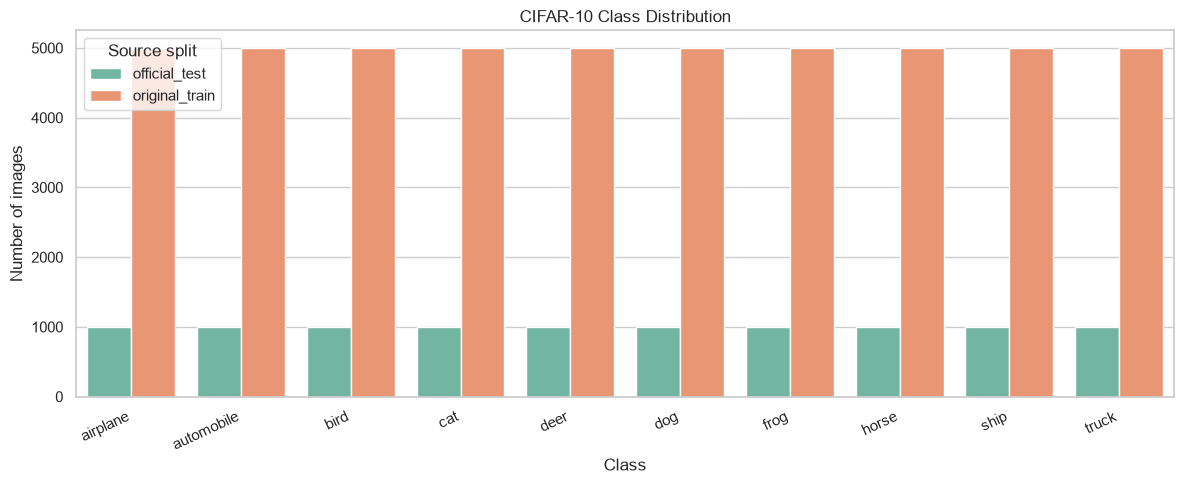

In [9]:
plt.figure(figsize=(12, 5))
sns.barplot(
    data=class_distribution,
    x="class_name",
    y="image_count",
    hue="source_split",
    palette="Set2",
)
plt.title("CIFAR-10 Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of images")
plt.xticks(rotation=25, ha="right")
plt.legend(title="Source split")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "figure_01_class_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

### Figure 2: Example Images by Class

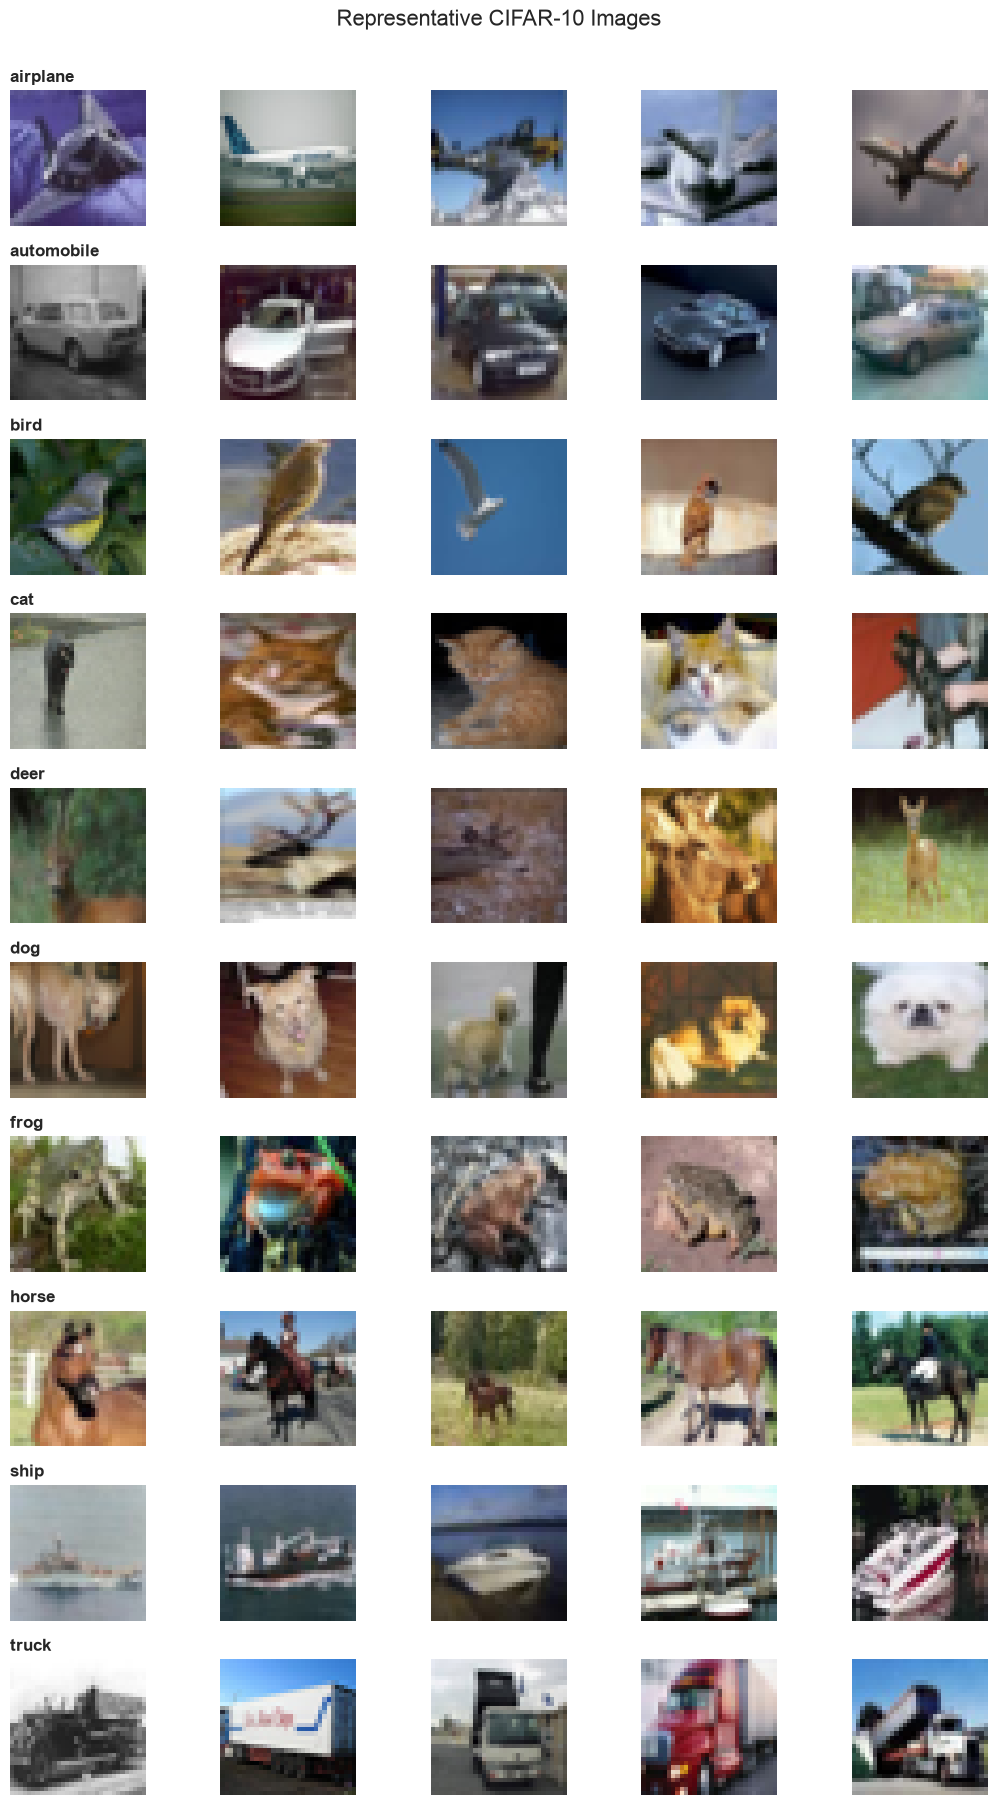

In [10]:
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(10, 5, figsize=(11, 18))

for class_id, class_name in enumerate(CLASS_NAMES):
    class_indices = np.where(y_train_full == class_id)[0]
    selected_indices = rng.choice(class_indices, size=5, replace=False)
    for column, image_index in enumerate(selected_indices):
        axes[class_id, column].imshow(x_train_full[image_index])
        axes[class_id, column].axis("off")
        if column == 0:
            axes[class_id, column].set_title(class_name, loc="left", fontweight="bold")

fig.suptitle("Representative CIFAR-10 Images", fontsize=16, y=1.002)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "figure_02_example_images.png", dpi=200, bbox_inches="tight")
plt.show()

In [11]:
# A small Pandas frame is collected from Spark for plotting summary statistics.
image_statistics = image_metadata_sdf.select(
    "source_split",
    "class_name",
    "red_mean",
    "green_mean",
    "blue_mean",
    "brightness",
    "contrast",
).toPandas()

image_statistics.head()

,source_split,class_name,red_mean,green_mean,blue_mean,brightness,contrast
0,original_train,frog,141.2051,105.0996,64.0371,103.4473,51.9737
1,original_train,truck,130.1992,130.3652,130.4775,130.3473,60.4792
2,original_train,truck,133.4844,135.1523,132.5850,133.7406,82.5632
3,original_train,deer,99.9795,83.2793,57.4141,80.2243,36.4719
4,original_train,automobile,92.0215,102.4004,116.0029,103.4749,60.5496


### Figure 3: Brightness by Class

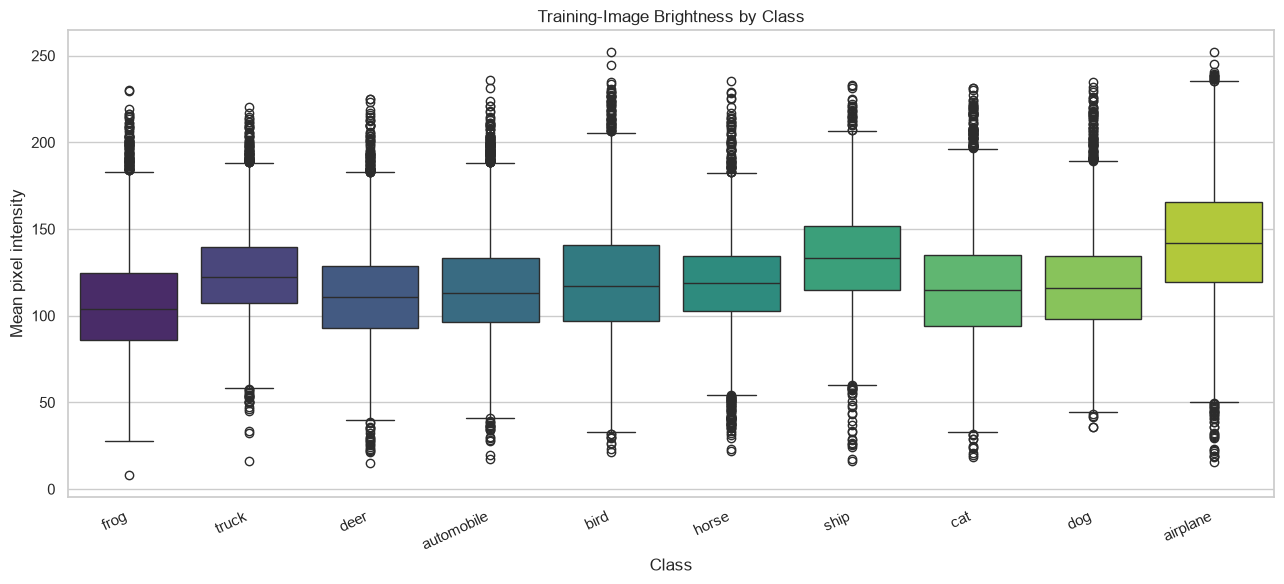

In [12]:
plt.figure(figsize=(13, 6))
sns.boxplot(
    data=image_statistics[image_statistics["source_split"] == "original_train"],
    x="class_name",
    y="brightness",
    palette="viridis",
)
plt.title("Training-Image Brightness by Class")
plt.xlabel("Class")
plt.ylabel("Mean pixel intensity")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "figure_03_brightness_by_class.png", dpi=200, bbox_inches="tight")
plt.show()

### Figure 4: Contrast by Class

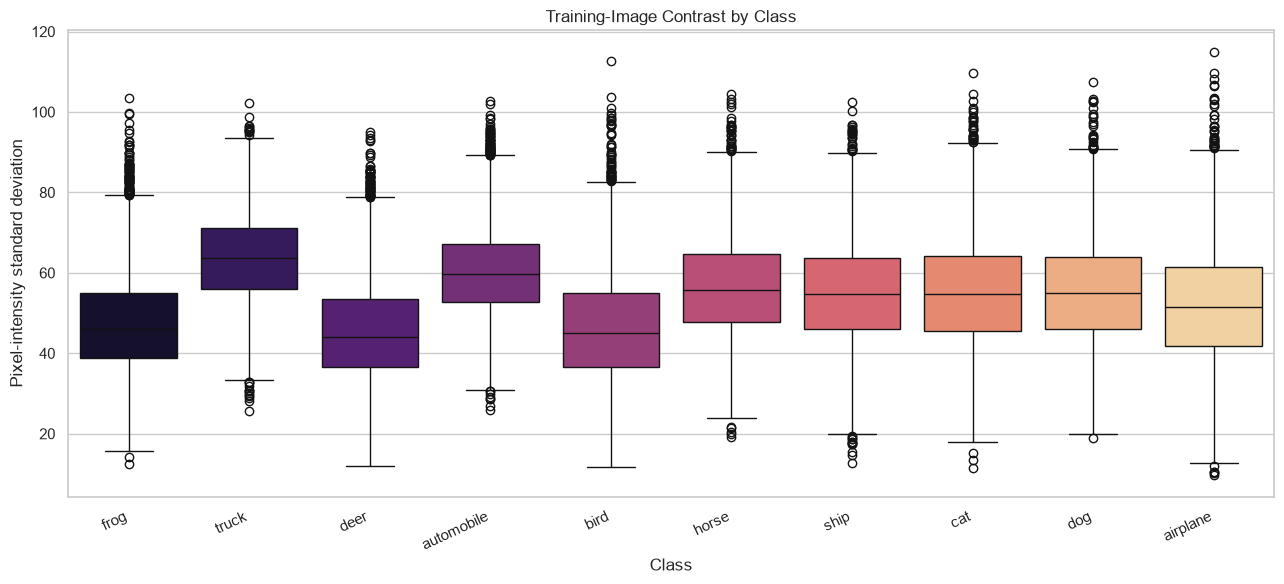

In [13]:
plt.figure(figsize=(13, 6))
sns.boxplot(
    data=image_statistics[image_statistics["source_split"] == "original_train"],
    x="class_name",
    y="contrast",
    palette="magma",
)
plt.title("Training-Image Contrast by Class")
plt.xlabel("Class")
plt.ylabel("Pixel-intensity standard deviation")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "figure_04_contrast_by_class.png", dpi=200, bbox_inches="tight")
plt.show()

### Figure 5: RGB Channel Distributions

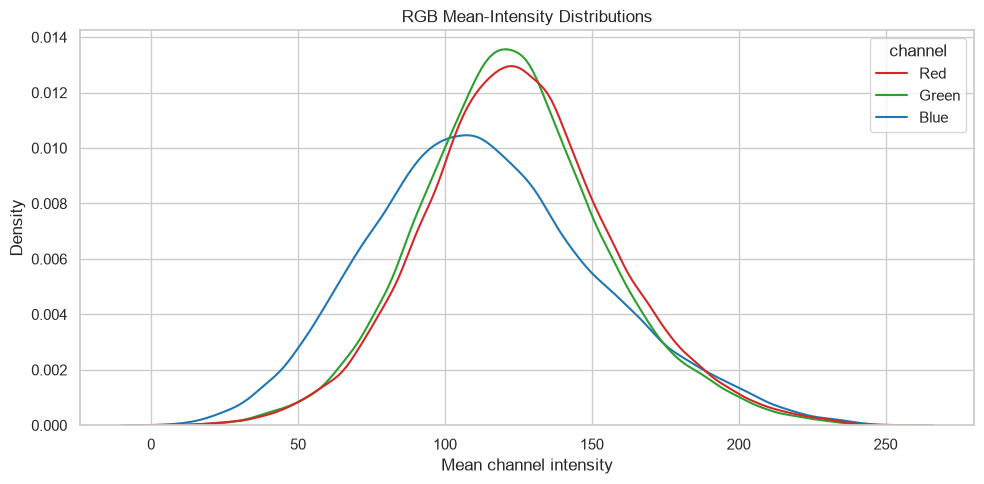

In [14]:
channel_data = image_statistics[image_statistics["source_split"] == "original_train"].melt(
    id_vars=["class_name"],
    value_vars=["red_mean", "green_mean", "blue_mean"],
    var_name="channel",
    value_name="mean_intensity",
)
channel_data["channel"] = channel_data["channel"].str.replace("_mean", "", regex=False).str.title()

plt.figure(figsize=(10, 5))
sns.kdeplot(
    data=channel_data,
    x="mean_intensity",
    hue="channel",
    common_norm=False,
    palette={"Red": "#d62728", "Green": "#2ca02c", "Blue": "#1f77b4"},
)
plt.title("RGB Mean-Intensity Distributions")
plt.xlabel("Mean channel intensity")
plt.ylabel("Density")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "figure_05_rgb_distributions.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. Feature Preparation and Data Splitting

In [15]:
# The official test data remain protected. Only the original training data are split.
x_train, x_val, y_train, y_val = train_test_split(
    x_train_full,
    y_train_full,
    test_size=VALIDATION_SIZE,
    stratify=y_train_full,
    random_state=SEED,
)

# CNN predictors are the spatial RGB pixels. IDs, checksums, split names and labels are excluded.
x_train = x_train.astype("float32") / 255.0
x_val = x_val.astype("float32") / 255.0
x_test_prepared = x_test.astype("float32") / 255.0

print("Training:", x_train.shape)
print("Validation:", x_val.shape)
print("Protected test:", x_test_prepared.shape)

Training: (45000, 32, 32, 3)
Validation: (5000, 32, 32, 3)
Protected test: (10000, 32, 32, 3)


### Table 4: Modelling Data Split

In [16]:
split_summary = pd.DataFrame({
    "Subset": ["Training", "Validation", "Protected test"],
    "Records": [len(x_train), len(x_val), len(x_test_prepared)],
    "Percentage of all data": [
        len(x_train) / 60000 * 100,
        len(x_val) / 60000 * 100,
        len(x_test_prepared) / 60000 * 100,
    ],
    "Purpose": [
        "Fit model parameters",
        "Compare models and control training",
        "One final evaluation after model selection",
    ],
})

split_summary.to_csv(TABLE_DIR / "table_04_modelling_split.csv", index=False)
split_summary

,Subset,Records,Percentage of all data,Purpose
0,Training,45000,75.0000,Fit model parameters
1,Validation,5000,8.3333,Compare models and control training
2,Protected test,10000,16.6667,One final evaluation after model selection


In [17]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = (
    tf.data.Dataset.from_tensor_slices((x_train, y_train))
    .shuffle(len(x_train), seed=SEED, reshuffle_each_iteration=True)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)
val_ds = (
    tf.data.Dataset.from_tensor_slices((x_val, y_val))
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)
test_ds = (
    tf.data.Dataset.from_tensor_slices((x_test_prepared, y_test))
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_ds).numpy())

Training batches: 352
Validation batches: 40
Test batches: 79


## 7. Training-Only Data Augmentation

In [18]:
def make_augmentation(name):
    return keras.Sequential([
        layers.RandomFlip("horizontal", seed=SEED),
        layers.RandomTranslation(0.10, 0.10, fill_mode="reflect", seed=SEED),
        layers.RandomRotation(0.05, fill_mode="reflect", seed=SEED),
        layers.RandomZoom(0.10, 0.10, fill_mode="reflect", seed=SEED),
    ], name=name)


augmentation_preview = make_augmentation("augmentation_preview")

### Figure 6: Data-Augmentation Examples

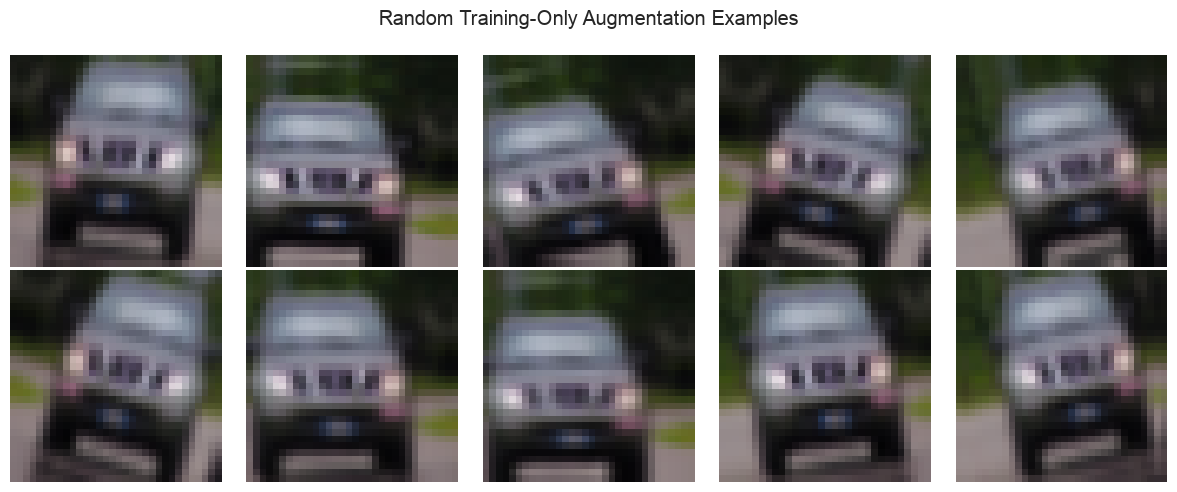

In [19]:
preview_image = x_train[:1]
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for axis in axes.flat:
    augmented_image = augmentation_preview(preview_image, training=True)[0].numpy()
    axis.imshow(np.clip(augmented_image, 0, 1))
    axis.axis("off")

plt.suptitle("Random Training-Only Augmentation Examples")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "figure_06_augmentation_examples.png", dpi=200, bbox_inches="tight")
plt.show()

## 8. Shared Model and Evaluation Functions

In [20]:
def make_callbacks(model_filename):
    return [
        keras.callbacks.ModelCheckpoint(
            MODEL_DIR / model_filename,
            monitor="val_loss",
            save_best_only=True,
            verbose=1,
        ),
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=7,
            restore_best_weights=True,
            verbose=1,
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=3,
            min_lr=1e-6,
            verbose=1,
        ),
    ]


def calculate_classification_metrics(y_true, probabilities, model_name):
    predictions = probabilities.argmax(axis=1)
    macro_precision, macro_recall, macro_f1, _ = precision_recall_fscore_support(
        y_true, predictions, average="macro", zero_division=0
    )
    weighted_precision, weighted_recall, weighted_f1, _ = precision_recall_fscore_support(
        y_true, predictions, average="weighted", zero_division=0
    )
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Macro precision": macro_precision,
        "Macro recall": macro_recall,
        "Macro F1": macro_f1,
        "Weighted precision": weighted_precision,
        "Weighted recall": weighted_recall,
        "Weighted F1": weighted_f1,
    }


def history_frame(history):
    frame = pd.DataFrame(history.history)
    frame.index = np.arange(1, len(frame) + 1)
    return frame

## 9. Model 1 - Baseline CNN

In [21]:
def build_baseline_cnn():
    inputs = keras.Input(shape=(32, 32, 3), name="image")
    x = layers.Conv2D(32, 3, padding="same", activation="relu", name="baseline_conv_1")(inputs)
    x = layers.MaxPooling2D(name="baseline_pool_1")(x)
    x = layers.Conv2D(64, 3, padding="same", activation="relu", name="baseline_last_conv")(x)
    x = layers.MaxPooling2D(name="baseline_pool_2")(x)
    x = layers.Flatten(name="baseline_flatten")(x)
    x = layers.Dense(128, activation="relu", name="baseline_dense")(x)
    x = layers.Dropout(0.30, name="baseline_dropout")(x)
    outputs = layers.Dense(10, activation="softmax", name="class_probabilities")(x)

    model = keras.Model(inputs, outputs, name="baseline_cnn")
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model


baseline_model = build_baseline_cnn()
baseline_model.summary()

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ baseline_conv_1 (Conv2D)        │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ baseline_pool_1 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ baseline_last_conv (Conv2D)     │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ baseline_pool_2 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ baseline_flatten (Flatten)      │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ baseline_dense (Dense)          │ (None, 128)            │       524,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ baseline_dropout (Dropout)      │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_probabilities (Dense)     │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 545,098 (2.08 MB)

 Trainable params: 545,098 (2.08 MB)

 Non-trainable params: 0 (0.00 B)

In [22]:
baseline_history = baseline_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=BASELINE_EPOCHS,
    verbose=1,
)

baseline_history_df = history_frame(baseline_history)
baseline_history_df.to_csv(TABLE_DIR / "baseline_training_history.csv", index_label="epoch")

Epoch 1/15
352/352 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - accuracy: 0.4246 - loss: 1.5852 - val_accuracy: 0.5610 - val_loss: 1.2409
Epoch 2/15
352/352 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.5576 - loss: 1.2491 - val_accuracy: 0.6006 - val_loss: 1.1177
Epoch 3/15
352/352 ━━━━━━━━━━━━━━━━━━━━ 11s 30ms/step - accuracy: 0.6051 - loss: 1.1174 - val_accuracy: 0.6428 - val_loss: 1.0137
Epoch 4/15
352/352 ━━━━━━━━━━━━━━━━━━━━ 11s 30ms/step - accuracy: 0.6375 - loss: 1.0326 - val_accuracy: 0.6612 - val_loss: 0.9690
Epoch 5/15
352/352 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.6602 - loss: 0.9652 - val_accuracy: 0.6734 - val_loss: 0.9218
Epoch 6/15
352/352 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.6803 - loss: 0.9130 - val_accuracy: 0.6956 - val_loss: 0.8912
Epoch 7/15
352/352 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.6949 - loss: 0.8681 - val_accuracy: 0.6956 - val_loss: 0.8652
Epoch 8/15
352/352 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.7111 - loss: 0.8230 - 

### Figure 7: Baseline CNN Accuracy

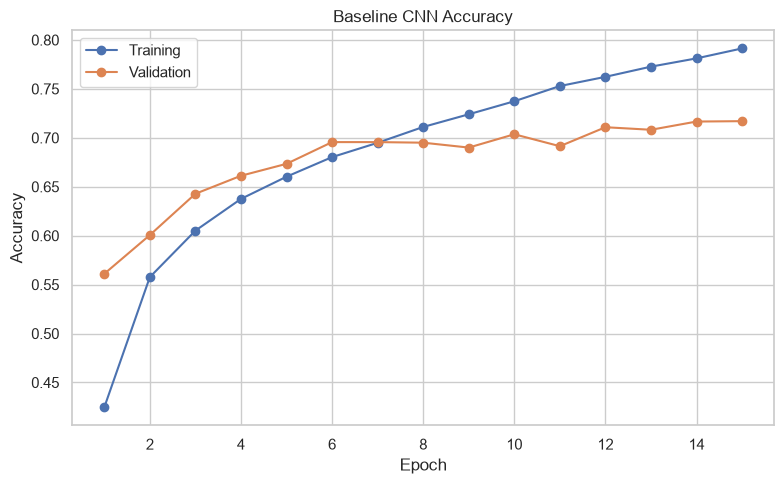

In [23]:
plt.figure(figsize=(8, 5))
plt.plot(baseline_history_df.index, baseline_history_df["accuracy"], marker="o", label="Training")
plt.plot(baseline_history_df.index, baseline_history_df["val_accuracy"], marker="o", label="Validation")
plt.title("Baseline CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "figure_07_baseline_accuracy.png", dpi=200, bbox_inches="tight")
plt.show()

### Figure 8: Baseline CNN Loss

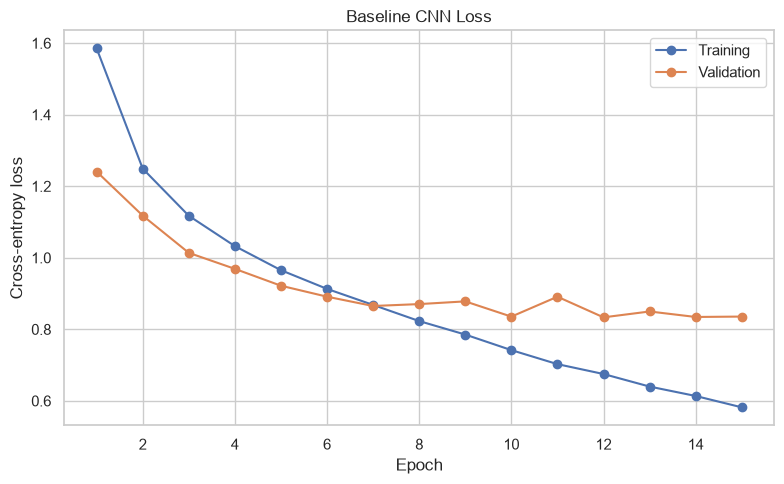

In [24]:
plt.figure(figsize=(8, 5))
plt.plot(baseline_history_df.index, baseline_history_df["loss"], marker="o", label="Training")
plt.plot(baseline_history_df.index, baseline_history_df["val_loss"], marker="o", label="Validation")
plt.title("Baseline CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "figure_08_baseline_loss.png", dpi=200, bbox_inches="tight")
plt.show()

In [25]:
baseline_val_probabilities = baseline_model.predict(val_ds, verbose=0)
baseline_val_metrics = calculate_classification_metrics(
    y_val, baseline_val_probabilities, "Baseline CNN"
)
pd.DataFrame([baseline_val_metrics])

,Model,Accuracy,Macro precision,Macro recall,Macro F1,Weighted precision,Weighted recall,Weighted F1
0,Baseline CNN,0.7170,0.7175,0.7170,0.7155,0.7175,0.7170,0.7155


## 10. Model 2 - Regularised CNN

In [26]:
def regularised_block(x, filters, block_name, dropout_rate):
    x = layers.Conv2D(
        filters, 3, padding="same", use_bias=False,
        kernel_regularizer=regularizers.l2(1e-4),
        name=f"{block_name}_conv_1",
    )(x)
    x = layers.BatchNormalization(name=f"{block_name}_bn_1")(x)
    x = layers.Activation("relu", name=f"{block_name}_relu_1")(x)
    x = layers.Conv2D(
        filters, 3, padding="same", use_bias=False,
        kernel_regularizer=regularizers.l2(1e-4),
        name=f"{block_name}_conv_2",
    )(x)
    x = layers.BatchNormalization(name=f"{block_name}_bn_2")(x)
    x = layers.Activation("relu", name=f"{block_name}_relu_2")(x)
    x = layers.MaxPooling2D(name=f"{block_name}_pool")(x)
    return layers.Dropout(dropout_rate, name=f"{block_name}_dropout")(x)


def build_regularised_cnn():
    inputs = keras.Input(shape=(32, 32, 3), name="image")
    x = make_augmentation("regularised_augmentation")(inputs)
    x = regularised_block(x, 32, "regularised_block_1", 0.15)
    x = regularised_block(x, 64, "regularised_block_2", 0.25)
    x = layers.Conv2D(
        128, 3, padding="same", use_bias=False,
        kernel_regularizer=regularizers.l2(1e-4),
        name="regularised_last_conv",
    )(x)
    x = layers.BatchNormalization(name="regularised_last_bn")(x)
    x = layers.Activation("relu", name="regularised_last_relu")(x)
    x = layers.GlobalAveragePooling2D(name="regularised_gap")(x)
    x = layers.Dense(128, activation="relu", name="regularised_dense")(x)
    x = layers.Dropout(0.40, name="regularised_final_dropout")(x)
    outputs = layers.Dense(10, activation="softmax", name="class_probabilities")(x)

    model = keras.Model(inputs, outputs, name="regularised_cnn")
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model


regularised_model = build_regularised_cnn()
regularised_model.summary()

Model: "regularised_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ regularised_augmentation        │ (None, 32, 32, 3)      │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ regularised_block_1_conv_1      │ (None, 32, 32, 32)     │           864 │
│ (Conv2D)                        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ regularised_block_1_bn_1        │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ regularised_block_1_relu_1      │ (None, 32, 32, 32)     │             0 │
│ (Activation)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ regularised_block_1_conv_2      │ (None, 32, 32, 32)     │         9,216 │
│ (Conv2D)                        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ regularised_block_1_bn_2        │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ regularised_block_1_relu_2      │ (None, 32, 32, 32)     │             0 │
│ (Activation)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ regularised_block_1_pool        │ (None, 16, 16, 32)     │             0 │
│ (MaxPooling2D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ regularised_block_1_dropout     │ (None, 16, 16, 32)     │             0 │
│ (Dropout)                       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ regularised_block_2_conv_1      │ (None, 16, 16, 64)     │        18,432 │
│ (Conv2D)                        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ regularised_block_2_bn_1        │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ regularised_block_2_relu_1      │ (None, 16, 16, 64)     │             0 │
│ (Activation)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ regularised_block_2_conv_2      │ (None, 16, 16, 64)     │        36,864 │
│ (Conv2D)                        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ regularised_block_2_bn_2        │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ regularised_block_2_relu_2      │ (None, 16, 16, 64)     │             0 │
│ (Activation)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ regularised_block_2_pool        │ (None, 8, 8, 64)       │             0 │
│ (MaxPooling2D)                  │                        │             

 Total params: 158,186 (617.91 KB)

 Trainable params: 157,546 (615.41 KB)

 Non-trainable params: 640 (2.50 KB)

In [27]:
regularised_history = regularised_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=REGULARISED_EPOCHS,
    callbacks=make_callbacks("regularised_cnn_best.keras"),
    verbose=1,
)

regularised_history_df = history_frame(regularised_history)
regularised_history_df.to_csv(TABLE_DIR / "regularised_training_history.csv", index_label="epoch")

Epoch 1/40
352/352 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step - accuracy: 0.3826 - loss: 1.6952
Epoch 1: val_loss improved from None to 1.90485, saving model to final_poe_outputs/models/regularised_cnn_best.keras

Epoch 1: finished saving model to final_poe_outputs/models/regularised_cnn_best.keras
352/352 ━━━━━━━━━━━━━━━━━━━━ 48s 128ms/step - accuracy: 0.3826 - loss: 1.6952 - val_accuracy: 0.3172 - val_loss: 1.9048 - learning_rate: 0.0010
Epoch 2/40
352/352 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step - accuracy: 0.5138 - loss: 1.3724
Epoch 2: val_loss improved from 1.90485 to 1.28005, saving model to final_poe_outputs/models/regularised_cnn_best.keras

Epoch 2: finished saving model to final_poe_outputs/models/regularised_cnn_best.keras
352/352 ━━━━━━━━━━━━━━━━━━━━ 45s 126ms/step - accuracy: 0.5138 - loss: 1.3724 - val_accuracy: 0.5550 - val_loss: 1.2801 - learning_rate: 0.0010
Epoch 3/40
352/352 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step - accuracy: 0.5634 - loss: 1.2447
Epoch 3: val_loss did not improve fro

### Figure 9: Regularised CNN Accuracy

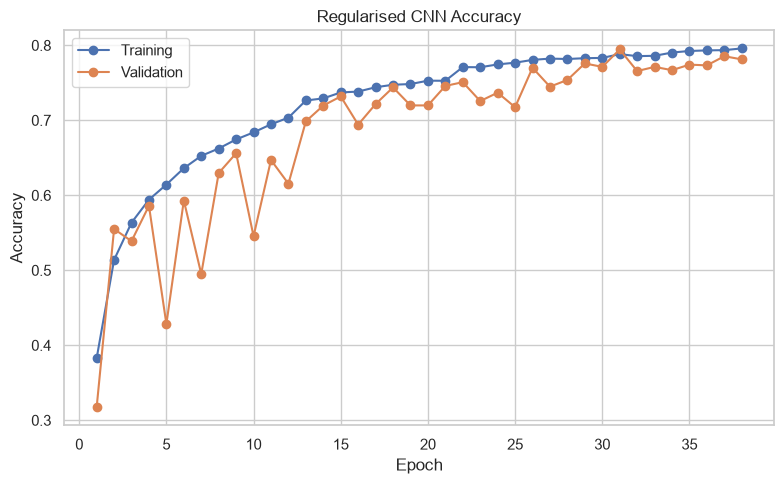

In [28]:
plt.figure(figsize=(8, 5))
plt.plot(regularised_history_df.index, regularised_history_df["accuracy"], marker="o", label="Training")
plt.plot(regularised_history_df.index, regularised_history_df["val_accuracy"], marker="o", label="Validation")
plt.title("Regularised CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "figure_09_regularised_accuracy.png", dpi=200, bbox_inches="tight")
plt.show()

### Figure 10: Regularised CNN Loss

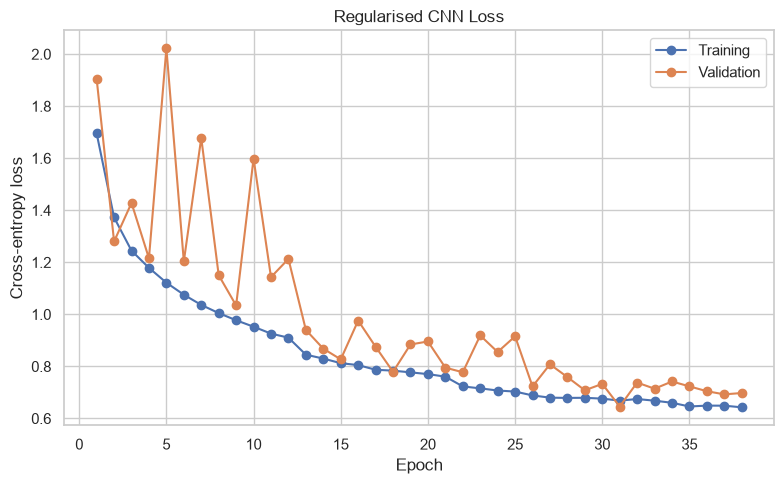

In [29]:
plt.figure(figsize=(8, 5))
plt.plot(regularised_history_df.index, regularised_history_df["loss"], marker="o", label="Training")
plt.plot(regularised_history_df.index, regularised_history_df["val_loss"], marker="o", label="Validation")
plt.title("Regularised CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "figure_10_regularised_loss.png", dpi=200, bbox_inches="tight")
plt.show()

In [30]:
regularised_val_probabilities = regularised_model.predict(val_ds, verbose=0)
regularised_val_metrics = calculate_classification_metrics(
    y_val, regularised_val_probabilities, "Regularised CNN"
)
pd.DataFrame([regularised_val_metrics])

,Model,Accuracy,Macro precision,Macro recall,Macro F1,Weighted precision,Weighted recall,Weighted F1
0,Regularised CNN,0.7944,0.7974,0.7944,0.7919,0.7974,0.7944,0.7919


## 11. Model 3 - Residual CNN

In [31]:
def residual_block(x, filters, stride, block_name):
    shortcut = x

    x = layers.Conv2D(
        filters, 3, strides=stride, padding="same", use_bias=False,
        kernel_regularizer=regularizers.l2(1e-4),
        name=f"{block_name}_conv_1",
    )(x)
    x = layers.BatchNormalization(name=f"{block_name}_bn_1")(x)
    x = layers.Activation("relu", name=f"{block_name}_relu_1")(x)
    x = layers.Conv2D(
        filters, 3, padding="same", use_bias=False,
        kernel_regularizer=regularizers.l2(1e-4),
        name=f"{block_name}_conv_2",
    )(x)
    x = layers.BatchNormalization(name=f"{block_name}_bn_2")(x)

    if stride != 1 or int(shortcut.shape[-1]) != filters:
        shortcut = layers.Conv2D(
            filters, 1, strides=stride, padding="same", use_bias=False,
            name=f"{block_name}_shortcut_conv",
        )(shortcut)
        shortcut = layers.BatchNormalization(name=f"{block_name}_shortcut_bn")(shortcut)

    x = layers.Add(name=f"{block_name}_add")([x, shortcut])
    return layers.Activation("relu", name=f"{block_name}_output")(x)


def build_residual_cnn():
    inputs = keras.Input(shape=(32, 32, 3), name="image")
    x = make_augmentation("residual_augmentation")(inputs)
    x = layers.Conv2D(32, 3, padding="same", use_bias=False, name="residual_stem_conv")(x)
    x = layers.BatchNormalization(name="residual_stem_bn")(x)
    x = layers.Activation("relu", name="residual_stem_relu")(x)
    x = residual_block(x, 32, 1, "residual_block_1")
    x = residual_block(x, 64, 2, "residual_block_2")
    x = residual_block(x, 64, 1, "residual_block_3")
    x = residual_block(x, 128, 2, "residual_block_4")
    x = residual_block(x, 128, 1, "residual_block_5")
    x = layers.GlobalAveragePooling2D(name="residual_gap")(x)
    x = layers.Dropout(0.35, name="residual_dropout")(x)
    outputs = layers.Dense(10, activation="softmax", name="class_probabilities")(x)

    model = keras.Model(inputs, outputs, name="residual_cnn")
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=8e-4),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model


residual_model = build_residual_cnn()
residual_model.summary()

Model: "residual_cnn"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)  │ (None, 32, 32, 3) │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ residual_augmentat… │ (None, 32, 32, 3) │          0 │ image[0][0]       │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ residual_stem_conv  │ (None, 32, 32,    │        864 │ residual_augment… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ residual_stem_bn    │ (None, 32, 32,    │        128 │ residual_stem_co… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ residual_stem_relu  │ (None, 32, 32,    │          0 │ residual_stem_bn… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ residual_block_1_c… │ (None, 32, 32,    │      9,216 │ residual_stem_re… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ residual_block_1_b… │ (None, 32, 32,    │        128 │ residual_block_1… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ residual_block_1_r… │ (None, 32, 32,    │          0 │ residual_block_1… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ residual_block_1_c… │ (None, 32, 32,    │      9,216 │ residual_block_1… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ residual_block_1_b… │ (None, 32, 32,    │        128 │ residual_block_1… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ residual_block_1_a… │ (None, 32, 32,    │          0 │ residual_block_1… │
│ (Add)               │ 32)               │            │ residual_stem_re… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ residual_block_1_o… │ (None, 32, 32,    │          0 │ residual_block_1… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ residual_block_2_c… │ (None, 16, 16,    │     18,432 │ residual_block_1… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ residual_block_2_b… │ (None, 16, 16,    │        256 │ residual_block_2… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ residual_block_2_r… │ (None, 16, 16,    │          0 │ residual_block_2… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ residual_block_2_c… │ (None, 16, 16,    │     36,864 │ residual_block_2… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ residual_block_2_s… │ (None, 16, 16,    │      2,048 │ residual_block_1… │
│ (Conv2D)            │ 64)               │            │                 

 Total params: 680,170 (2.59 MB)

 Trainable params: 678,058 (2.59 MB)

 Non-trainable params: 2,112 (8.25 KB)

In [32]:
residual_history = residual_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=RESIDUAL_EPOCHS,
    callbacks=make_callbacks("residual_cnn_best.keras"),
    verbose=1,
)

residual_history_df = history_frame(residual_history)
residual_history_df.to_csv(TABLE_DIR / "residual_training_history.csv", index_label="epoch")

Epoch 1/40
352/352 ━━━━━━━━━━━━━━━━━━━━ 0s 268ms/step - accuracy: 0.4138 - loss: 1.6887
Epoch 1: val_loss improved from None to 4.48241, saving model to final_poe_outputs/models/residual_cnn_best.keras

Epoch 1: finished saving model to final_poe_outputs/models/residual_cnn_best.keras
352/352 ━━━━━━━━━━━━━━━━━━━━ 102s 277ms/step - accuracy: 0.4138 - loss: 1.6887 - val_accuracy: 0.1494 - val_loss: 4.4824 - learning_rate: 8.0000e-04
Epoch 2/40
352/352 ━━━━━━━━━━━━━━━━━━━━ 0s 262ms/step - accuracy: 0.5702 - loss: 1.2873
Epoch 2: val_loss improved from 4.48241 to 1.91657, saving model to final_poe_outputs/models/residual_cnn_best.keras

Epoch 2: finished saving model to final_poe_outputs/models/residual_cnn_best.keras
352/352 ━━━━━━━━━━━━━━━━━━━━ 95s 270ms/step - accuracy: 0.5702 - loss: 1.2873 - val_accuracy: 0.4626 - val_loss: 1.9166 - learning_rate: 8.0000e-04
Epoch 3/40
352/352 ━━━━━━━━━━━━━━━━━━━━ 0s 261ms/step - accuracy: 0.6378 - loss: 1.1136
Epoch 3: val_loss improved from 1.91657 

### Figure 11: Residual CNN Accuracy

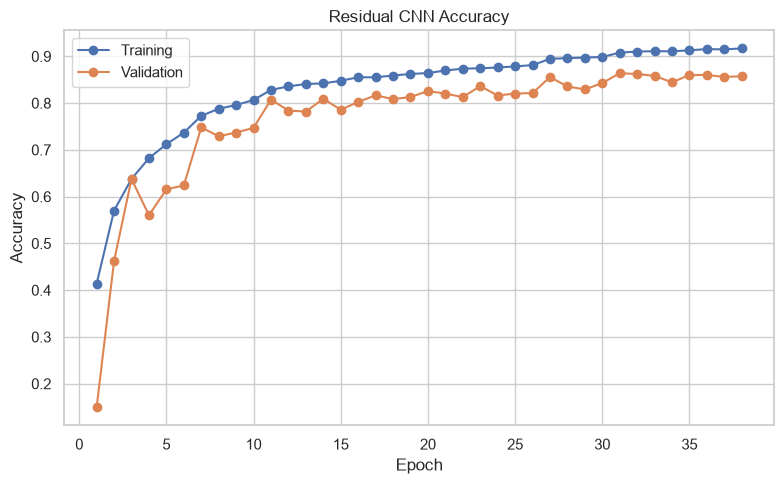

In [33]:
plt.figure(figsize=(8, 5))
plt.plot(residual_history_df.index, residual_history_df["accuracy"], marker="o", label="Training")
plt.plot(residual_history_df.index, residual_history_df["val_accuracy"], marker="o", label="Validation")
plt.title("Residual CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "figure_11_residual_accuracy.png", dpi=200, bbox_inches="tight")
plt.show()

### Figure 12: Residual CNN Loss

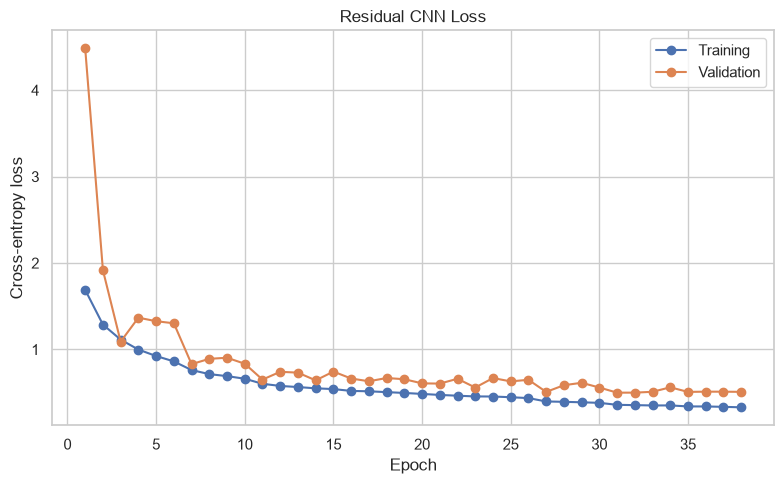

In [34]:
plt.figure(figsize=(8, 5))
plt.plot(residual_history_df.index, residual_history_df["loss"], marker="o", label="Training")
plt.plot(residual_history_df.index, residual_history_df["val_loss"], marker="o", label="Validation")
plt.title("Residual CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "figure_12_residual_loss.png", dpi=200, bbox_inches="tight")
plt.show()

In [35]:
residual_val_probabilities = residual_model.predict(val_ds, verbose=0)
residual_val_metrics = calculate_classification_metrics(
    y_val, residual_val_probabilities, "Residual CNN"
)
pd.DataFrame([residual_val_metrics])

,Model,Accuracy,Macro precision,Macro recall,Macro F1,Weighted precision,Weighted recall,Weighted F1
0,Residual CNN,0.8638,0.8628,0.8638,0.8627,0.8628,0.8638,0.8627


## 12. Validation Comparison and Model Selection

### Table 5: Model Configuration Summary

In [36]:
model_configuration_summary = pd.DataFrame([
    {
        "Model": "Baseline CNN",
        "Parameters": baseline_model.count_params(),
        "Augmentation": "No",
        "Batch normalisation": "No",
        "L2 regularisation": "No",
        "Skip connections": "No",
        "Maximum epochs": BASELINE_EPOCHS,
    },
    {
        "Model": "Regularised CNN",
        "Parameters": regularised_model.count_params(),
        "Augmentation": "Yes",
        "Batch normalisation": "Yes",
        "L2 regularisation": "Yes",
        "Skip connections": "No",
        "Maximum epochs": REGULARISED_EPOCHS,
    },
    {
        "Model": "Residual CNN",
        "Parameters": residual_model.count_params(),
        "Augmentation": "Yes",
        "Batch normalisation": "Yes",
        "L2 regularisation": "Yes",
        "Skip connections": "Yes",
        "Maximum epochs": RESIDUAL_EPOCHS,
    },
])

model_configuration_summary.to_csv(TABLE_DIR / "table_05_model_configuration.csv", index=False)
model_configuration_summary

,Model,Parameters,Augmentation,Batch normalisation,L2 regularisation,Skip connections,Maximum epochs
0,Baseline CNN,545098,No,No,No,No,15
1,Regularised CNN,158186,Yes,Yes,Yes,No,40
2,Residual CNN,680170,Yes,Yes,Yes,Yes,40


### Table 6: Validation Model Comparison

In [37]:
validation_comparison = pd.DataFrame([
    baseline_val_metrics,
    regularised_val_metrics,
    residual_val_metrics,
]).sort_values("Macro F1", ascending=False).reset_index(drop=True)

validation_comparison.to_csv(TABLE_DIR / "table_06_validation_comparison.csv", index=False)
validation_comparison

,Model,Accuracy,Macro precision,Macro recall,Macro F1,Weighted precision,Weighted recall,Weighted F1
0,Residual CNN,0.8638,0.8628,0.8638,0.8627,0.8628,0.8638,0.8627
1,Regularised CNN,0.7944,0.7974,0.7944,0.7919,0.7974,0.7944,0.7919
2,Baseline CNN,0.7170,0.7175,0.7170,0.7155,0.7175,0.7170,0.7155


### Figure 13: Validation Model Comparison

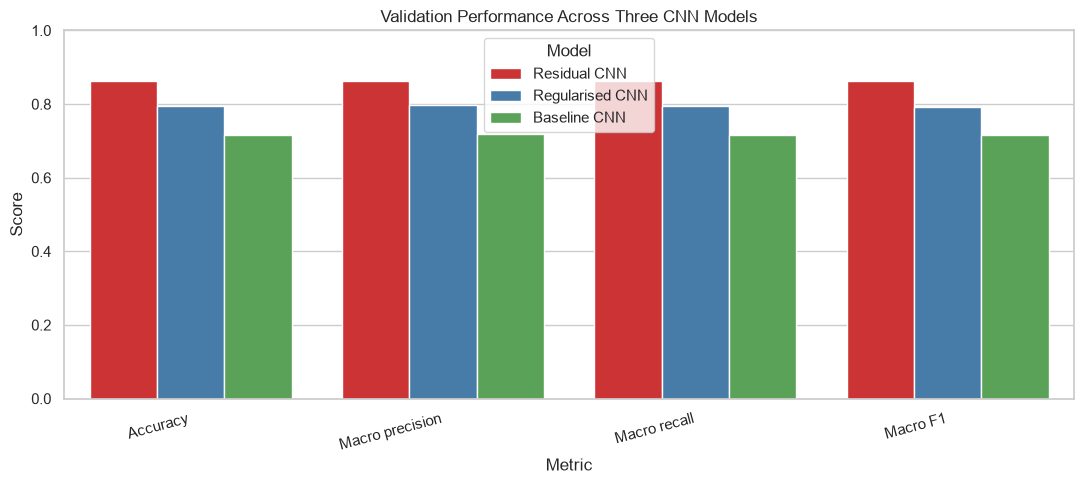

In [38]:
validation_plot_data = validation_comparison.melt(
    id_vars="Model",
    value_vars=["Accuracy", "Macro precision", "Macro recall", "Macro F1"],
    var_name="Metric",
    value_name="Score",
)

plt.figure(figsize=(11, 5))
sns.barplot(data=validation_plot_data, x="Metric", y="Score", hue="Model", palette="Set1")
plt.ylim(0, 1)
plt.title("Validation Performance Across Three CNN Models")
plt.xlabel("Metric")
plt.ylabel("Score")
plt.xticks(rotation=15, ha="right")
plt.legend(title="Model")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "figure_13_validation_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

In [39]:
# Selection uses validation macro F1 only. The test set has not yet been scored.
selected_model_name = validation_comparison.loc[0, "Model"]
model_lookup = {
    "Baseline CNN": baseline_model,
    "Regularised CNN": regularised_model,
    "Residual CNN": residual_model,
}
selected_model = model_lookup[selected_model_name]

print("Selected model:", selected_model_name)
print("Selection metric: validation macro F1")

Selected model: Residual CNN
Selection metric: validation macro F1


## 13. Final Evaluation on the Protected Test Set

In [40]:
# This is the first use of the protected test set for model scoring.
test_loss, _ = selected_model.evaluate(test_ds, verbose=0)
test_probabilities = selected_model.predict(test_ds, verbose=0)
test_predictions = test_probabilities.argmax(axis=1)
y_test_binary = label_binarize(y_test, classes=np.arange(10))

final_test_metrics = calculate_classification_metrics(
    y_test, test_probabilities, selected_model_name
)
final_test_metrics["Cross-entropy loss"] = float(test_loss)
final_test_metrics["Macro ROC-AUC OvR"] = roc_auc_score(
    y_test_binary,
    test_probabilities,
    average="macro",
    multi_class="ovr",
)
final_test_metrics["Macro average precision"] = average_precision_score(
    y_test_binary,
    test_probabilities,
    average="macro",
)

### Table 7: Final Test Metrics

In [41]:
final_test_metrics_df = pd.DataFrame([final_test_metrics])
final_test_metrics_df.to_csv(TABLE_DIR / "table_07_final_test_metrics.csv", index=False)
final_test_metrics_df.T.rename(columns={0: "Test result"})

,Test result
Model,Residual CNN
Accuracy,0.8448
Macro precision,0.8448
Macro recall,0.8448
Macro F1,0.8436
Weighted precision,0.8448
Weighted recall,0.8448
Weighted F1,0.8436
Cross-entropy loss,0.5505
Macro ROC-AUC OvR,0.9873


### Table 8: Final Classification Report

In [42]:
classification_report_df = pd.DataFrame(
    classification_report(
        y_test,
        test_predictions,
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0,
    )
).T

classification_report_df.to_csv(TABLE_DIR / "table_08_classification_report.csv")
classification_report_df

,precision,recall,f1-score,support
airplane,0.8119,0.8890,0.8487,"1,000.0000"
automobile,0.8967,0.9550,0.9249,"1,000.0000"
bird,0.7837,0.8080,0.7957,"1,000.0000"
cat,0.7517,0.6810,0.7146,"1,000.0000"
deer,0.8768,0.7830,0.8273,"1,000.0000"
dog,0.8036,0.7490,0.7754,"1,000.0000"
frog,0.8249,0.9140,0.8672,"1,000.0000"
horse,0.9052,0.8500,0.8767,"1,000.0000"
ship,0.9210,0.8980,0.9094,"1,000.0000"
truck,0.8722,0.9210,0.8959,"1,000.0000"


### Figure 14: Confusion Matrix - Counts

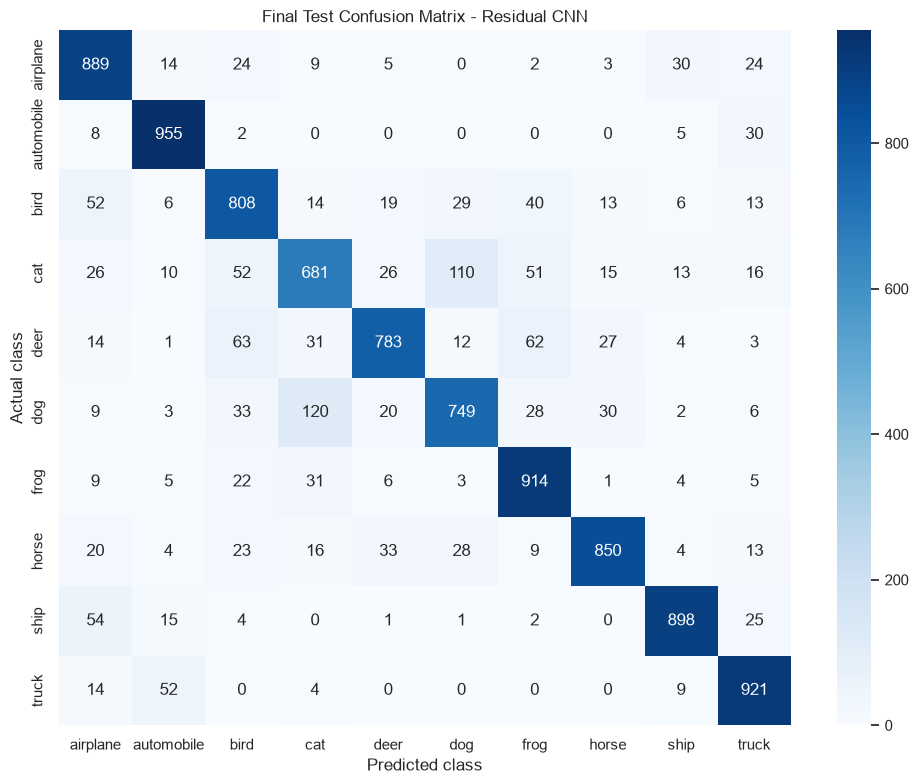

In [43]:
test_confusion_matrix = confusion_matrix(y_test, test_predictions)

plt.figure(figsize=(10, 8))
sns.heatmap(
    test_confusion_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
)
plt.title(f"Final Test Confusion Matrix - {selected_model_name}")
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "figure_14_confusion_matrix_counts.png", dpi=200, bbox_inches="tight")
plt.show()

### Figure 15: Normalised Confusion Matrix

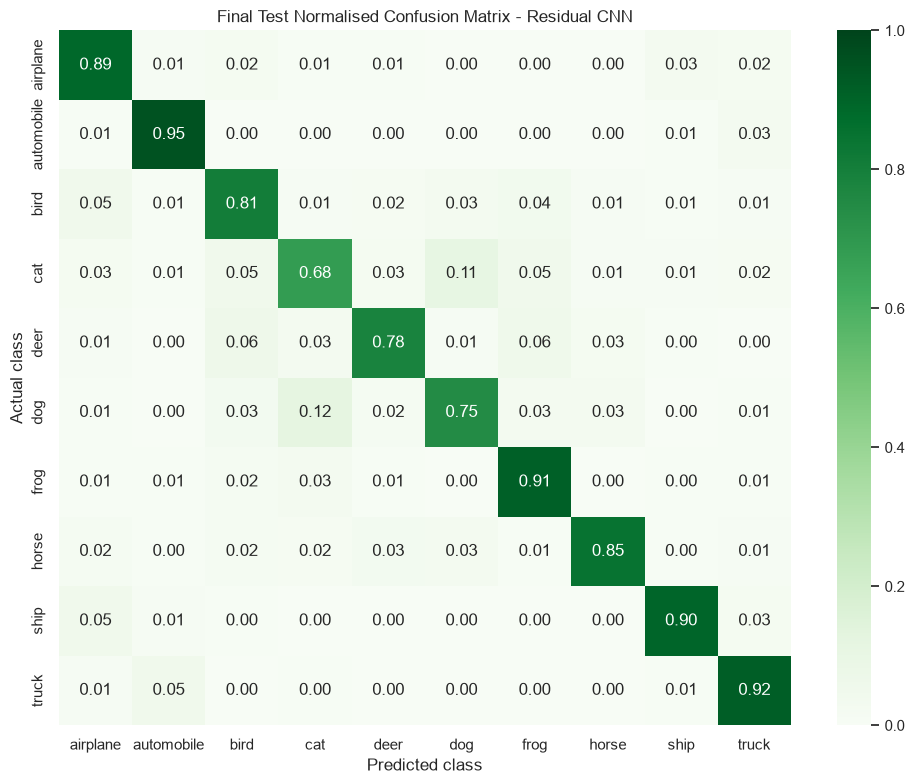

In [44]:
normalised_confusion_matrix = confusion_matrix(y_test, test_predictions, normalize="true")

plt.figure(figsize=(10, 8))
sns.heatmap(
    normalised_confusion_matrix,
    annot=True,
    fmt=".2f",
    cmap="Greens",
    vmin=0,
    vmax=1,
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
)
plt.title(f"Final Test Normalised Confusion Matrix - {selected_model_name}")
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "figure_15_confusion_matrix_normalised.png", dpi=200, bbox_inches="tight")
plt.show()

### Figure 16: Per-Class F1 Scores

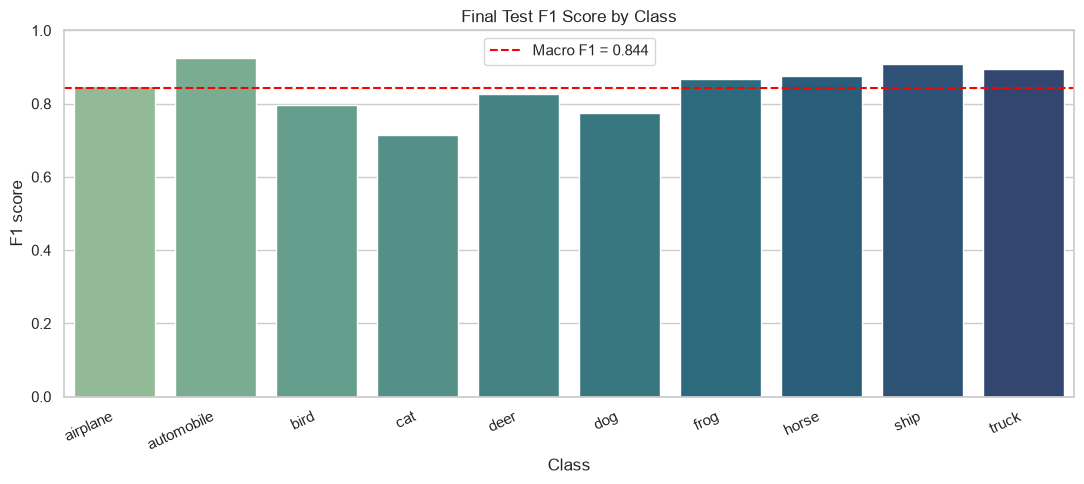

In [45]:
per_class_metrics = classification_report_df.loc[CLASS_NAMES].reset_index().rename(
    columns={"index": "class_name"}
)

plt.figure(figsize=(11, 5))
sns.barplot(data=per_class_metrics, x="class_name", y="f1-score", palette="crest")
plt.axhline(
    final_test_metrics["Macro F1"],
    color="red",
    linestyle="--",
    label=f"Macro F1 = {final_test_metrics['Macro F1']:.3f}",
)
plt.ylim(0, 1)
plt.title("Final Test F1 Score by Class")
plt.xlabel("Class")
plt.ylabel("F1 score")
plt.xticks(rotation=25, ha="right")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "figure_16_per_class_f1.png", dpi=200, bbox_inches="tight")
plt.show()

### Figure 17: One-vs-Rest ROC Curves

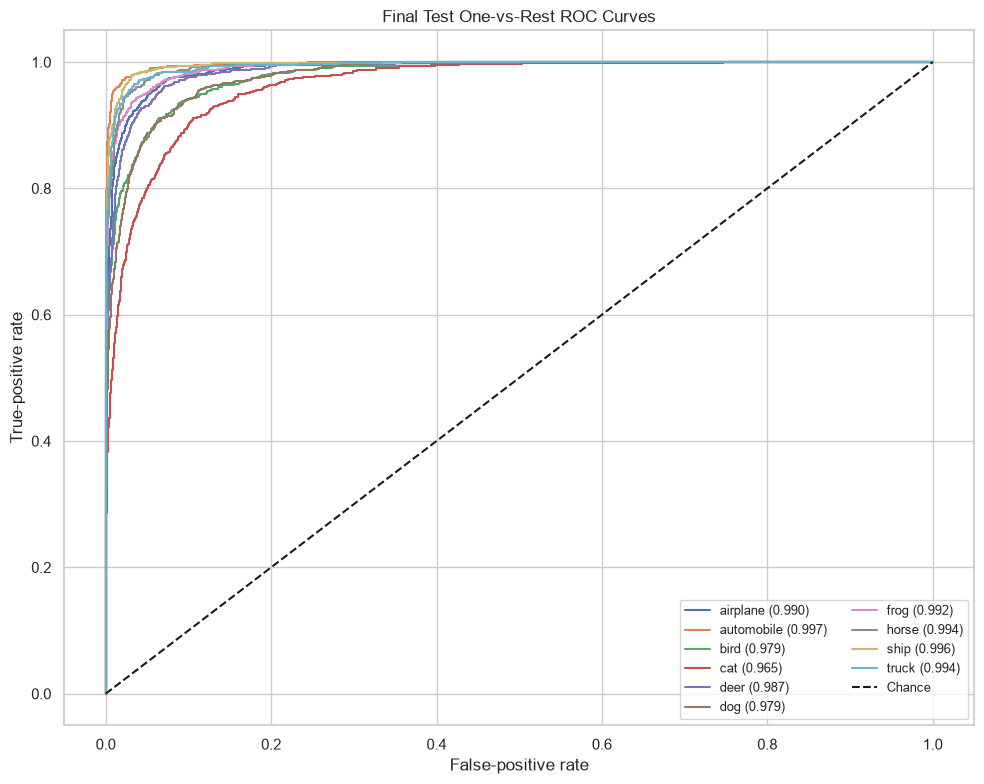

In [46]:
plt.figure(figsize=(10, 8))

for class_id, class_name in enumerate(CLASS_NAMES):
    false_positive_rate, true_positive_rate, _ = roc_curve(
        y_test_binary[:, class_id],
        test_probabilities[:, class_id],
    )
    class_auc = auc(false_positive_rate, true_positive_rate)
    plt.plot(false_positive_rate, true_positive_rate, label=f"{class_name} ({class_auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.title("Final Test One-vs-Rest ROC Curves")
plt.xlabel("False-positive rate")
plt.ylabel("True-positive rate")
plt.legend(loc="lower right", ncol=2, fontsize=9)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "figure_17_roc_curves.png", dpi=200, bbox_inches="tight")
plt.show()

### Figure 18: One-vs-Rest Precision-Recall Curves

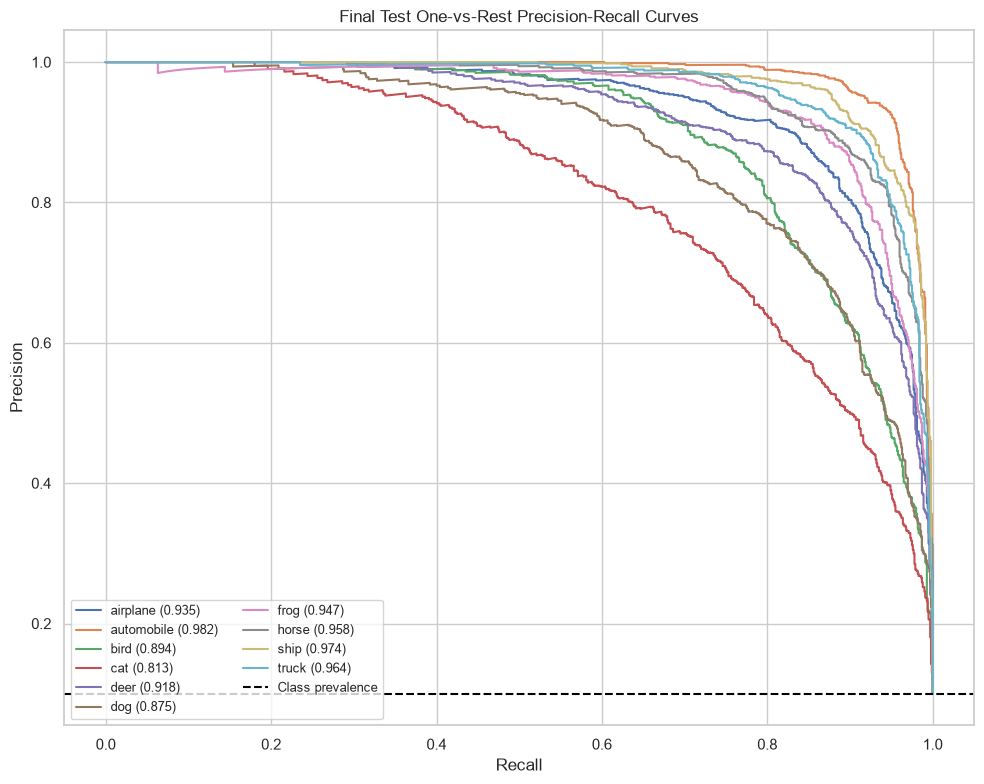

In [47]:
plt.figure(figsize=(10, 8))

for class_id, class_name in enumerate(CLASS_NAMES):
    class_precision, class_recall, _ = precision_recall_curve(
        y_test_binary[:, class_id],
        test_probabilities[:, class_id],
    )
    class_ap = average_precision_score(
        y_test_binary[:, class_id],
        test_probabilities[:, class_id],
    )
    plt.plot(class_recall, class_precision, label=f"{class_name} ({class_ap:.3f})")

plt.axhline(0.10, color="black", linestyle="--", label="Class prevalence")
plt.title("Final Test One-vs-Rest Precision-Recall Curves")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend(loc="lower left", ncol=2, fontsize=9)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "figure_18_precision_recall_curves.png", dpi=200, bbox_inches="tight")
plt.show()

## 14. Confidence, Calibration and Error Analysis

In [48]:
test_confidence = test_probabilities.max(axis=1)
test_correct = test_predictions == y_test

confidence_df = pd.DataFrame({
    "confidence": test_confidence,
    "correct": test_correct,
    "actual_class": CLASS_NAMES[y_test],
    "predicted_class": CLASS_NAMES[test_predictions],
})

confidence_df.groupby("correct")["confidence"].describe()

,count,mean,std,min,25%,50%,75%,max
correct,,,,,,,,
False,"1,552.0000",0.6606,0.1998,0.2070,0.5019,0.6503,0.8314,1.0000
True,"8,448.0000",0.9253,0.1370,0.2347,0.9247,0.9936,0.9997,1.0000


### Figure 19: Prediction Confidence Distribution

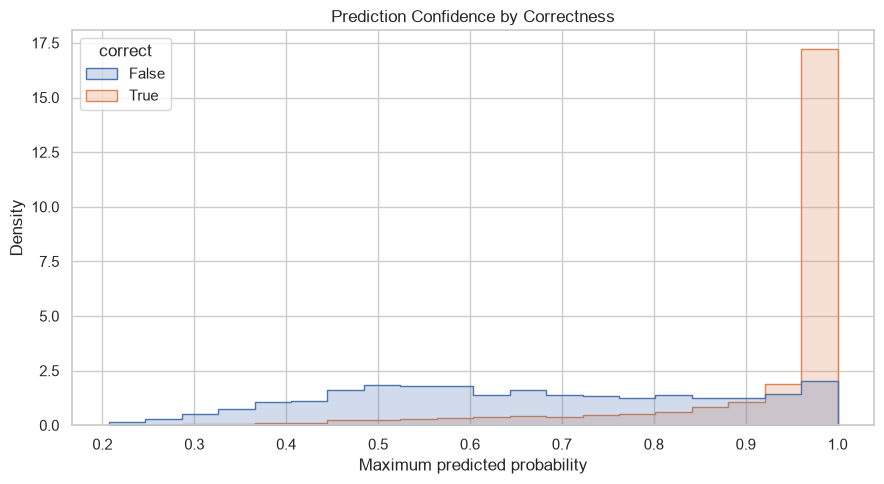

In [49]:
plt.figure(figsize=(9, 5))
sns.histplot(
    data=confidence_df,
    x="confidence",
    hue="correct",
    bins=20,
    stat="density",
    common_norm=False,
    element="step",
)
plt.title("Prediction Confidence by Correctness")
plt.xlabel("Maximum predicted probability")
plt.ylabel("Density")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "figure_19_confidence_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

In [50]:
def calculate_calibration(y_true, probabilities, number_of_bins=10):
    predictions = probabilities.argmax(axis=1)
    confidence = probabilities.max(axis=1)
    correctness = (predictions == y_true).astype(float)
    bin_edges = np.linspace(0, 1, number_of_bins + 1)
    rows = []
    expected_calibration_error = 0.0

    for lower, upper in zip(bin_edges[:-1], bin_edges[1:]):
        if upper == 1.0:
            mask = (confidence >= lower) & (confidence <= upper)
        else:
            mask = (confidence >= lower) & (confidence < upper)

        if mask.sum() == 0:
            continue

        observed_accuracy = correctness[mask].mean()
        mean_confidence = confidence[mask].mean()
        absolute_gap = abs(observed_accuracy - mean_confidence)
        expected_calibration_error += mask.mean() * absolute_gap

        rows.append({
            "Lower bound": lower,
            "Upper bound": upper,
            "Count": int(mask.sum()),
            "Mean confidence": mean_confidence,
            "Observed accuracy": observed_accuracy,
            "Absolute gap": absolute_gap,
        })

    return pd.DataFrame(rows), expected_calibration_error


calibration_df, expected_calibration_error = calculate_calibration(
    y_test, test_probabilities
)

### Table 9: Probability Calibration

In [51]:
calibration_df.to_csv(TABLE_DIR / "table_09_probability_calibration.csv", index=False)
print(f"Expected calibration error: {expected_calibration_error:.4f}")
calibration_df

Expected calibration error: 0.0394


,Lower bound,Upper bound,Count,Mean confidence,Observed accuracy,Absolute gap
0,0.2000,0.3000,41,0.2685,0.1707,0.0978
1,0.3000,0.4000,186,0.3551,0.3172,0.0379
2,0.4000,0.5000,367,0.4579,0.3896,0.0683
3,0.5000,0.6000,538,0.5520,0.4870,0.0650
4,0.6000,0.7000,556,0.6500,0.5881,0.0619
5,0.7000,0.8000,604,0.7516,0.6540,0.0976
6,0.8000,0.9000,858,0.8541,0.7657,0.0883
7,0.9000,1.0000,6850,0.9857,0.9632,0.0225


### Figure 20: Reliability Diagram

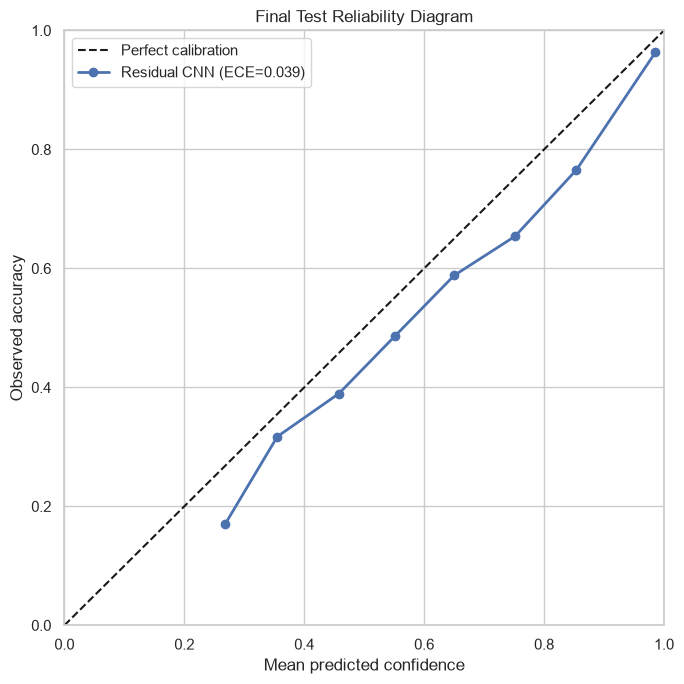

In [52]:
plt.figure(figsize=(7, 7))
plt.plot([0, 1], [0, 1], "k--", label="Perfect calibration")
plt.plot(
    calibration_df["Mean confidence"],
    calibration_df["Observed accuracy"],
    marker="o",
    linewidth=2,
    label=f"{selected_model_name} (ECE={expected_calibration_error:.3f})",
)
plt.title("Final Test Reliability Diagram")
plt.xlabel("Mean predicted confidence")
plt.ylabel("Observed accuracy")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "figure_20_reliability_diagram.png", dpi=200, bbox_inches="tight")
plt.show()

In [53]:
confusion_without_diagonal = test_confusion_matrix.copy()
np.fill_diagonal(confusion_without_diagonal, 0)

confusion_rows = []
for actual_id in range(10):
    for predicted_id in range(10):
        count = int(confusion_without_diagonal[actual_id, predicted_id])
        if count > 0:
            confusion_rows.append({
                "Actual class": CLASS_NAMES[actual_id],
                "Predicted class": CLASS_NAMES[predicted_id],
                "Count": count,
            })

top_confusions = (
    pd.DataFrame(confusion_rows)
    .sort_values("Count", ascending=False)
    .head(15)
    .reset_index(drop=True)
)

### Table 10: Most Frequent Class Confusions

In [54]:
top_confusions.to_csv(TABLE_DIR / "table_10_top_confusions.csv", index=False)
top_confusions

,Actual class,Predicted class,Count
0,dog,cat,120
1,cat,dog,110
2,deer,bird,63
3,deer,frog,62
4,ship,airplane,54
5,cat,bird,52
6,truck,automobile,52
7,bird,airplane,52
8,cat,frog,51
9,bird,frog,40


### Figure 21: Most Frequent Class Confusions

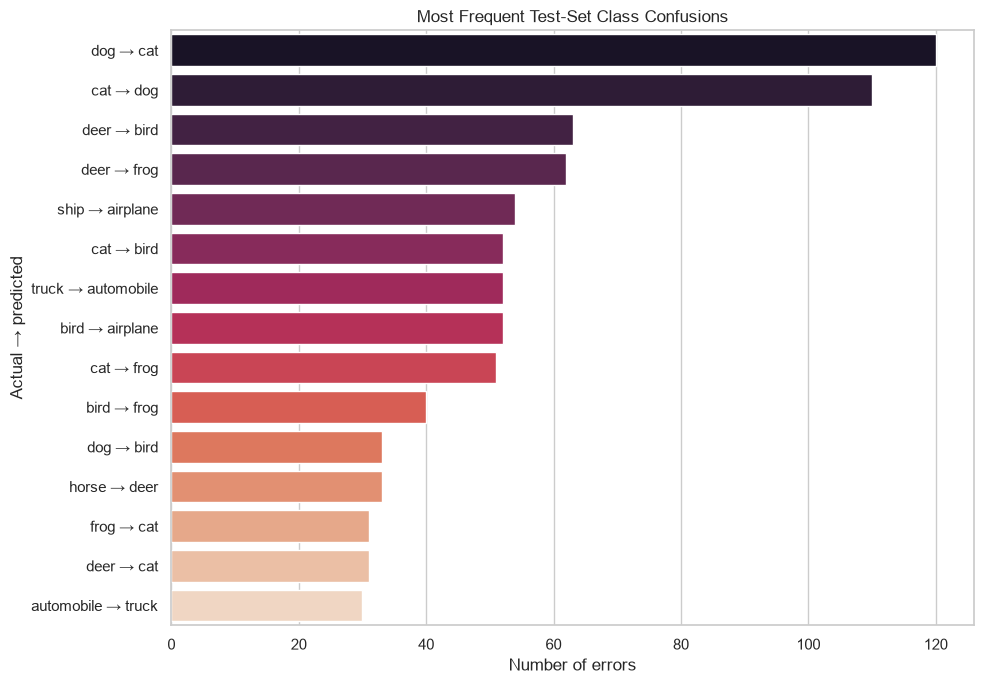

In [55]:
confusion_plot_data = top_confusions.copy()
confusion_plot_data["Confusion"] = (
    confusion_plot_data["Actual class"] + " → " + confusion_plot_data["Predicted class"]
)

plt.figure(figsize=(10, 7))
sns.barplot(
    data=confusion_plot_data,
    y="Confusion",
    x="Count",
    palette="rocket",
)
plt.title("Most Frequent Test-Set Class Confusions")
plt.xlabel("Number of errors")
plt.ylabel("Actual → predicted")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "figure_21_top_confusions.png", dpi=200, bbox_inches="tight")
plt.show()

### Figure 22: High-Confidence Misclassifications

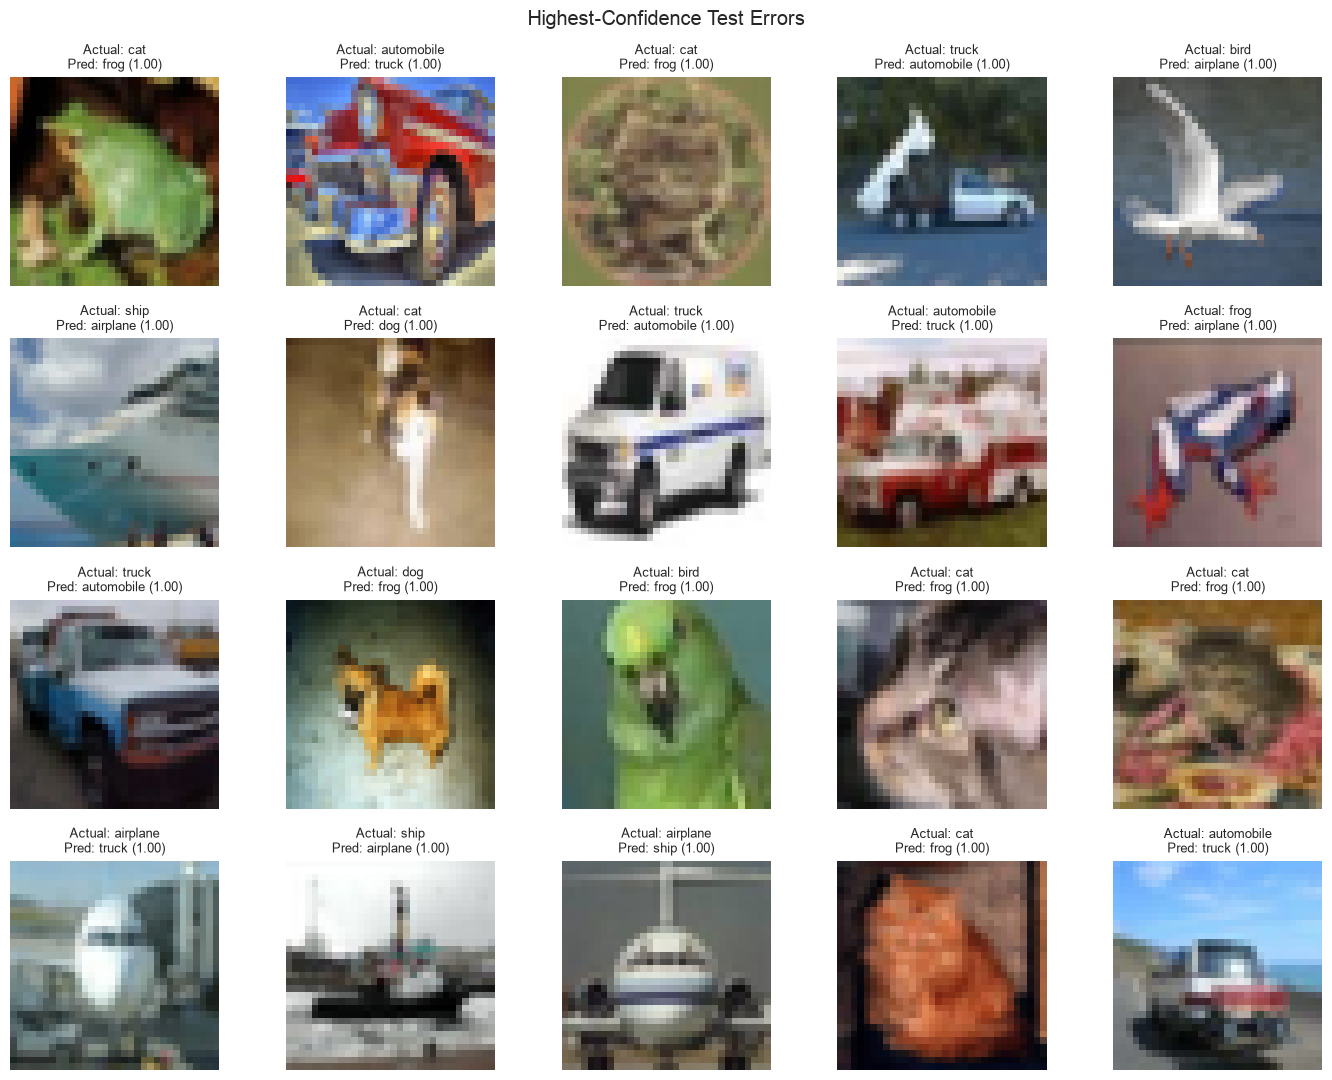

In [56]:
misclassified_indices = np.where(~test_correct)[0]
high_confidence_errors = misclassified_indices[
    np.argsort(test_confidence[misclassified_indices])[::-1]
][:20]

fig, axes = plt.subplots(4, 5, figsize=(14, 11))
for axis, image_index in zip(axes.flat, high_confidence_errors):
    axis.imshow(x_test[image_index])
    axis.set_title(
        f"Actual: {CLASS_NAMES[y_test[image_index]]}\n"
        f"Pred: {CLASS_NAMES[test_predictions[image_index]]} "
        f"({test_confidence[image_index]:.2f})",
        fontsize=9,
    )
    axis.axis("off")

for axis in axes.flat[len(high_confidence_errors):]:
    axis.axis("off")

plt.suptitle("Highest-Confidence Test Errors")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "figure_22_high_confidence_errors.png", dpi=200, bbox_inches="tight")
plt.show()

### Figure 23: Correct High-Confidence Predictions

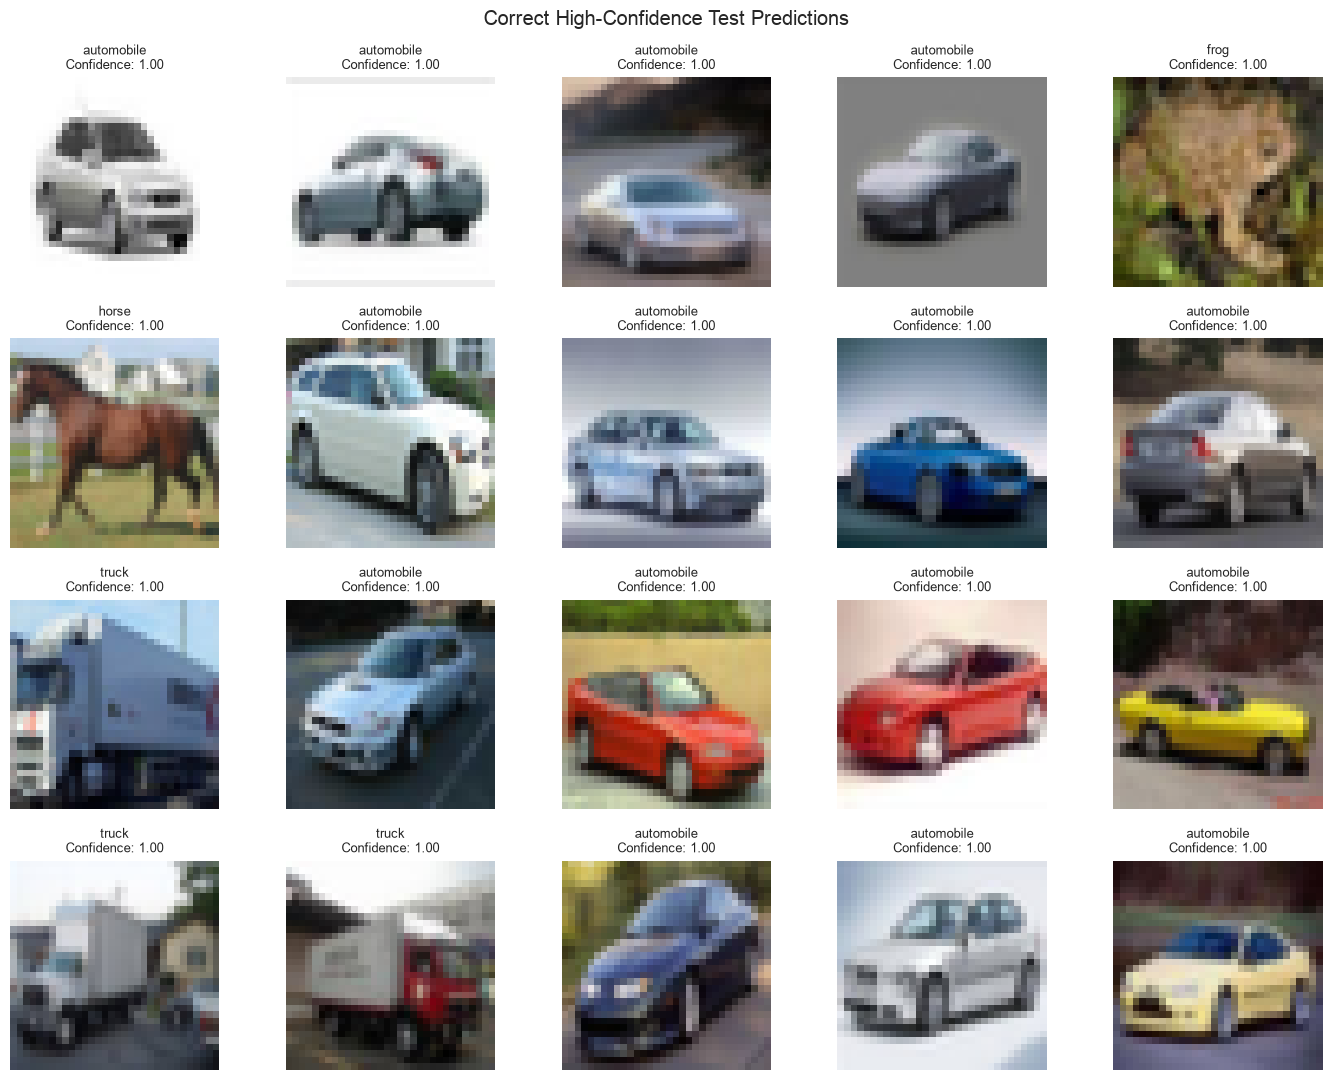

In [57]:
correct_indices = np.where(test_correct)[0]
high_confidence_correct = correct_indices[
    np.argsort(test_confidence[correct_indices])[::-1]
][:20]

fig, axes = plt.subplots(4, 5, figsize=(14, 11))
for axis, image_index in zip(axes.flat, high_confidence_correct):
    axis.imshow(x_test[image_index])
    axis.set_title(
        f"{CLASS_NAMES[y_test[image_index]]}\n"
        f"Confidence: {test_confidence[image_index]:.2f}",
        fontsize=9,
    )
    axis.axis("off")

plt.suptitle("Correct High-Confidence Test Predictions")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "figure_23_correct_high_confidence.png", dpi=200, bbox_inches="tight")
plt.show()

## 15. Grad-CAM and Client Demonstration

In [58]:
def make_gradcam_heatmap(image_batch, model, last_conv_layer_name):
    grad_model = keras.Model(
        model.inputs,
        [model.get_layer(last_conv_layer_name).output, model.output],
    )

    with tf.GradientTape() as tape:
        convolution_output, predictions = grad_model(image_batch, training=False)
        predicted_class = tf.argmax(predictions[0])
        class_score = predictions[:, predicted_class]

    gradients = tape.gradient(class_score, convolution_output)
    pooled_gradients = tf.reduce_mean(gradients, axis=(0, 1, 2))
    convolution_output = convolution_output[0]
    heatmap = convolution_output @ pooled_gradients[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy(), int(predicted_class.numpy())


def overlay_heatmap(original_image, heatmap, alpha=0.45):
    heatmap_uint8 = np.uint8(255 * heatmap)
    colour_map = plt.get_cmap("jet")
    heatmap_colours = colour_map(np.arange(256))[:, :3]
    coloured_heatmap = heatmap_colours[heatmap_uint8]
    coloured_heatmap = tf.image.resize(coloured_heatmap, (32, 32)).numpy()
    base_image = original_image.astype("float32") / 255.0
    return np.clip((1 - alpha) * base_image + alpha * coloured_heatmap, 0, 1)


gradcam_layer_lookup = {
    "Baseline CNN": "baseline_last_conv",
    "Regularised CNN": "regularised_last_conv",
    "Residual CNN": "residual_block_5_conv_2",
}
selected_gradcam_layer = gradcam_layer_lookup[selected_model_name]

### Figure 24: Grad-CAM Explanations

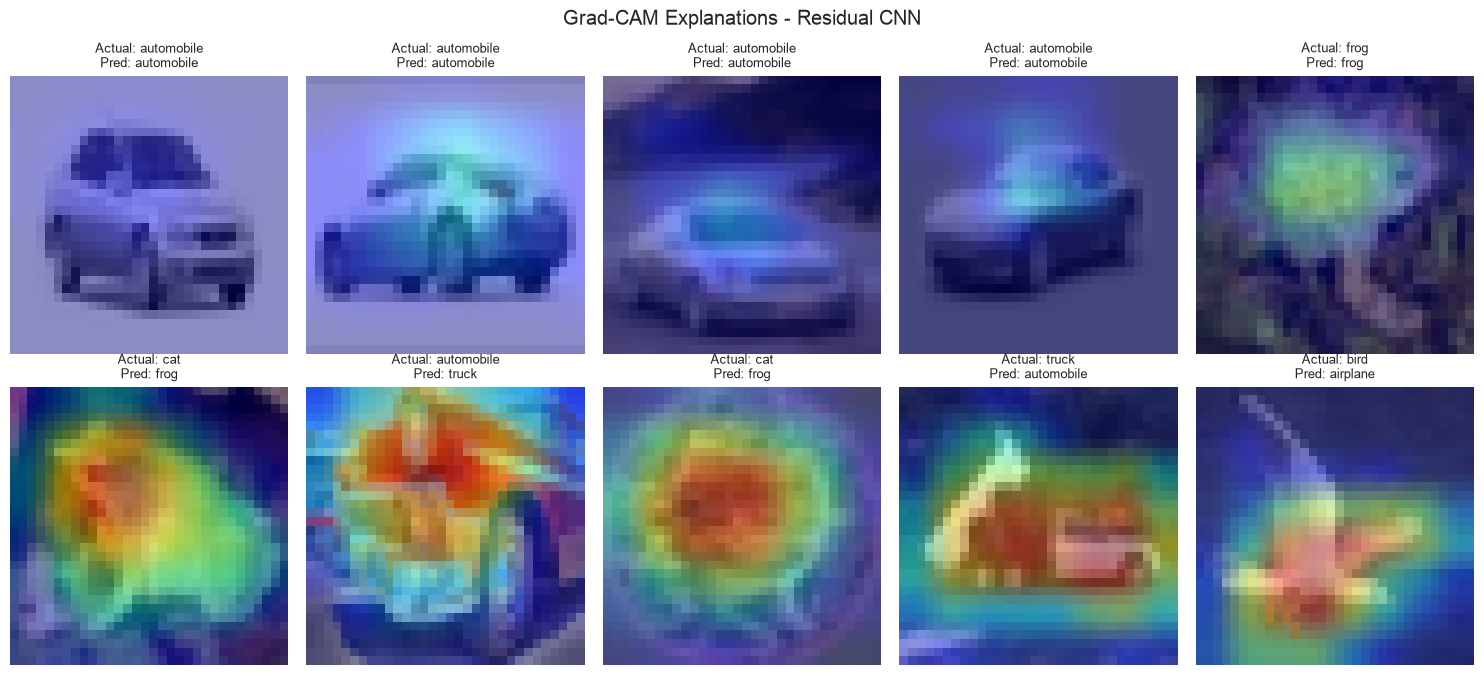

In [59]:
gradcam_indices = np.concatenate([
    high_confidence_correct[:5],
    high_confidence_errors[:5],
])

fig, axes = plt.subplots(2, 5, figsize=(15, 7))
for axis, image_index in zip(axes.flat, gradcam_indices):
    heatmap, predicted_class = make_gradcam_heatmap(
        x_test_prepared[image_index:image_index + 1],
        selected_model,
        selected_gradcam_layer,
    )
    axis.imshow(overlay_heatmap(x_test[image_index], heatmap))
    axis.set_title(
        f"Actual: {CLASS_NAMES[y_test[image_index]]}\n"
        f"Pred: {CLASS_NAMES[predicted_class]}",
        fontsize=9,
    )
    axis.axis("off")

plt.suptitle(f"Grad-CAM Explanations - {selected_model_name}")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "figure_24_gradcam.png", dpi=200, bbox_inches="tight")
plt.show()

In [60]:
demonstration_indices = np.random.default_rng(SEED).choice(
    len(x_test_prepared), size=10, replace=False
)

demonstration_rows = []
for image_index in demonstration_indices:
    ranked_class_ids = np.argsort(test_probabilities[image_index])[::-1][:3]
    demonstration_rows.append({
        "Test index": int(image_index),
        "Actual class": CLASS_NAMES[y_test[image_index]],
        "Top prediction": CLASS_NAMES[ranked_class_ids[0]],
        "Top probability": float(test_probabilities[image_index, ranked_class_ids[0]]),
        "Second prediction": CLASS_NAMES[ranked_class_ids[1]],
        "Second probability": float(test_probabilities[image_index, ranked_class_ids[1]]),
        "Third prediction": CLASS_NAMES[ranked_class_ids[2]],
        "Third probability": float(test_probabilities[image_index, ranked_class_ids[2]]),
        "Correct": bool(ranked_class_ids[0] == y_test[image_index]),
    })

demonstration_df = pd.DataFrame(demonstration_rows)

### Table 11: Client Demonstration Predictions

In [61]:
demonstration_df.to_csv(TABLE_DIR / "table_11_client_demonstration.csv", index=False)
demonstration_df

,Test index,Actual class,Top prediction,Top probability,Second prediction,Second probability,Third prediction,Third probability,Correct
0,859,ship,ship,0.9999,truck,0.0001,automobile,0.0000,True
1,7733,airplane,airplane,0.9993,bird,0.0006,ship,0.0001,True
2,891,frog,frog,1.0000,bird,0.0000,cat,0.0000,True
3,6541,ship,ship,0.7230,airplane,0.2609,automobile,0.0098,True
4,4386,frog,frog,0.9921,bird,0.0071,airplane,0.0003,True
5,4327,automobile,automobile,1.0000,truck,0.0000,airplane,0.0000,True
6,6972,automobile,automobile,1.0000,truck,0.0000,airplane,0.0000,True
7,941,automobile,automobile,0.6346,airplane,0.2754,truck,0.0802,True
8,2014,ship,ship,0.9985,airplane,0.0014,deer,0.0000,True
9,8582,frog,frog,0.9992,bird,0.0005,deer,0.0002,True


### Figure 25: Client Image-Recognition Demonstration

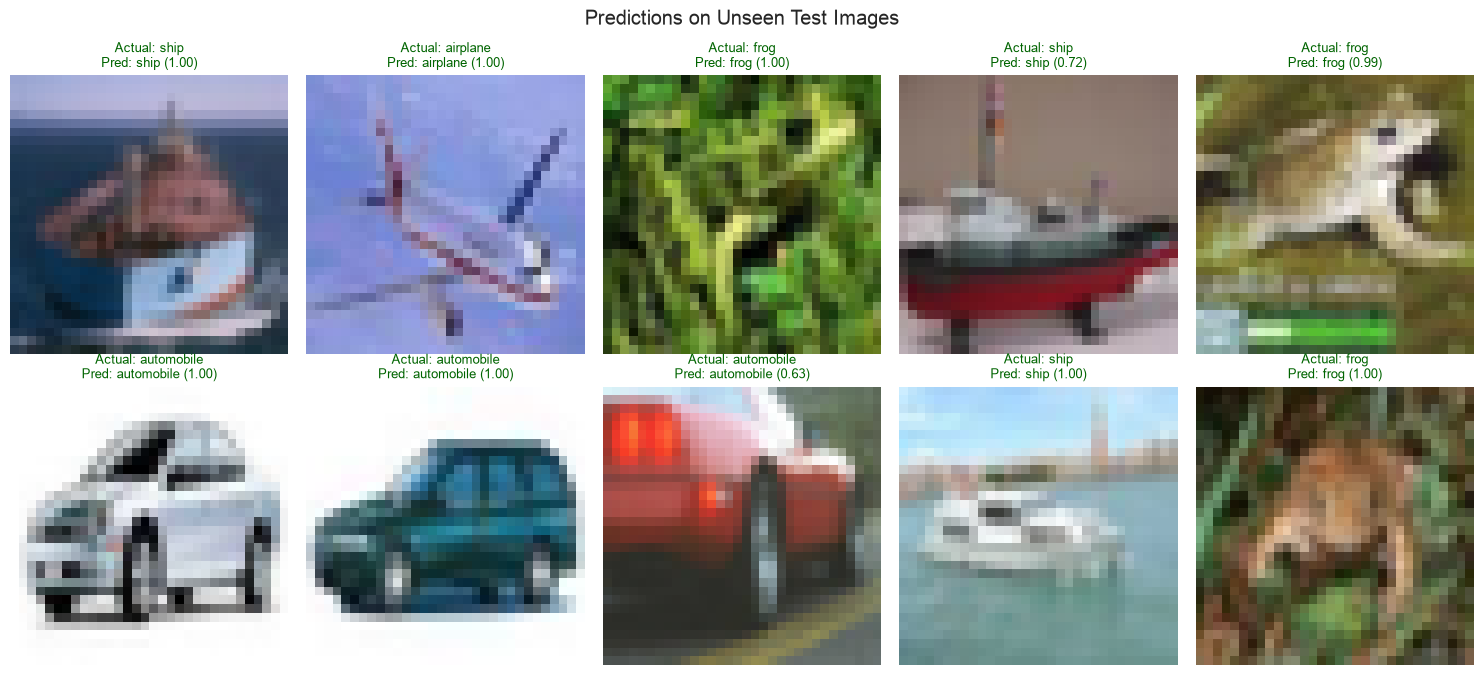

In [62]:
fig, axes = plt.subplots(2, 5, figsize=(15, 7))

for axis, image_index in zip(axes.flat, demonstration_indices):
    predicted_id = test_predictions[image_index]
    title_colour = "darkgreen" if predicted_id == y_test[image_index] else "darkred"
    axis.imshow(x_test[image_index])
    axis.set_title(
        f"Actual: {CLASS_NAMES[y_test[image_index]]}\n"
        f"Pred: {CLASS_NAMES[predicted_id]} ({test_confidence[image_index]:.2f})",
        color=title_colour,
        fontsize=9,
    )
    axis.axis("off")

plt.suptitle("Predictions on Unseen Test Images")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "figure_25_client_demonstration.png", dpi=200, bbox_inches="tight")
plt.show()

## 16. Save Models and Outputs

In [63]:
selected_model_path = MODEL_DIR / "selected_cifar10_cnn.keras"
selected_model.save(selected_model_path)

label_map = {int(index): str(class_name) for index, class_name in enumerate(CLASS_NAMES)}
with open(OUTPUT_DIR / "label_map.json", "w", encoding="utf-8") as file:
    json.dump(label_map, file, indent=2)

run_metadata = {
    "student": "Boitumelo Malinga",
    "student_number": "ST10107491",
    "dataset": "CIFAR-10",
    "seed": SEED,
    "fast_mode": FAST_MODE,
    "selected_model": selected_model_name,
    "selection_metric": "validation macro F1",
    "training_records": int(len(x_train)),
    "validation_records": int(len(x_val)),
    "test_records": int(len(x_test_prepared)),
    "expected_calibration_error": float(expected_calibration_error),
    "final_test_metrics": {
        key: float(value) if isinstance(value, (float, np.floating)) else value
        for key, value in final_test_metrics.items()
    },
    "tensorflow_version": tf.__version__,
    "pyspark_version": pyspark.__version__,
}

with open(OUTPUT_DIR / "run_metadata.json", "w", encoding="utf-8") as file:
    json.dump(run_metadata, file, indent=2)

print("Selected model saved to:", selected_model_path)
print("All outputs saved to:", OUTPUT_DIR.resolve())

Selected model saved to: final_poe_outputs/models/selected_cifar10_cnn.keras
All outputs saved to: /Users/boitumelomalinga/Documents/PDAN8412_Final_POE/final_poe_outputs


In [64]:
image_metadata_sdf.unpersist()
spark.stop()
print("Spark session stopped successfully.")

Spark session stopped successfully.
